In [1]:
from rdkit import Chem

import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data
from torch_geometric.data import InMemoryDataset
from torch_geometric.loader import DataLoader

import torch.nn as nn
import torch.nn.functional as F
import torch_geometric.nn as pyg_nn
from tqdm.auto import tqdm

from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Descriptors
from rdkit.Chem.rdMolDescriptors import CalcNumHBA
from rdkit.Chem.rdMolDescriptors import CalcNumHBD
import os
import matplotlib.pyplot as plt
#os.chdir('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF')  # 실제 파일이 있는 상위 폴더로 변경 (vs code의 remote SSH 사용시 위치 잘 못잡아서..)

In [2]:
import socket, os, torch
print("host:", socket.gethostname())
print("pid:", os.getpid())
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device:", torch.cuda.get_device_name(0))

host: ufslab223
pid: 1019079
cuda available: True
device: NVIDIA GeForce RTX 3090


In [34]:
# gpu 메모리 비우기
torch.cuda.empty_cache()

In [3]:
# PE --> Propane, Hexane
# 용매 비율은 어떻게 전파시킬까??

## bring primary processed & filtered DB

### filtering 위해 모든 데이터 통합 후 filtering함
### DataSource 칼럼에 'D4C', 'benchmark'로 분류해둠 (benchmark = nat.commun)
### 두 출처로 분류해서 train 과 test에 같은 비율로 분배해하기 

In [6]:
# C_Rf, Q_Rf 개별 웅용 어떻게 될지 몰라서 일단 필터링만 하고 중복 제거는 안된 데이터 불러옴

united = pd.read_csv('./DB/collecting/filtered_data/united_filter_no_drop_dup.csv')
#united_567 = pd.read_csv('./DB/collecting/filtered_data/united_filter_567_no_drop_dup.csv')
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54056,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.614610,0.385390,0.498683,C,benchmark,exp (benchmark
54057,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.443636,0.556364,0.662423,C,benchmark,exp (benchmark
54058,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54059,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.443636,0.556364,0.010664,C,benchmark,exp (benchmark


In [7]:
# salt 데이터 삭제

united = united[united['Smiles'].str.find('.')==-1]
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,CCC(=O)C(Cc1ccc(Br)cc1)C(=O)CC,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.400000,Q,D4C,10.1021/acs.orglett.3c03369
1,O=C(O)C(Cc1ccc(Br)cc1)C(=O)O,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.050000,Q,D4C,10.1021/acs.orglett.3c03369
2,O=C(O)CCc1ccc(Br)cc1,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.100000,Q,D4C,10.1021/acs.orglett.3c03369
3,O=C1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.650000,Q,D4C,10.1021/acs.orglett.3c03369
4,OC1CCc2ccc(Br)cc21,CCCCCC,CCOC(C)=O,0.636120,0.363880,0.550000,Q,D4C,10.1021/acs.orglett.3c03369
...,...,...,...,...,...,...,...,...,...
54056,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.614610,0.385390,0.498683,C,benchmark,exp (benchmark
54057,CC1CCC(=O)c2ccccc21,CCCCCC,CCOCC,0.443636,0.556364,0.662423,C,benchmark,exp (benchmark
54058,CC1CCC(=O)c2ccccc21,CCOCC,NaN,1.000000,0.000000,0.988897,C,benchmark,exp (benchmark
54059,O=C1CCCc2cccnc21,CCCCCC,CCOCC,0.443636,0.556364,0.010664,C,benchmark,exp (benchmark


In [8]:
# 중복 제거!!
# 중복 데이터 평균 내기
# D4C 이랑 benchmark에서 겹치는거 있으면 데이터소스는 d4c으로 처리하는 중


#--------PE hex---------
united = united.groupby(
    by=['Smiles', 'elu1_smiles', 'elu2_smiles', 'ratio1', 'ratio2'],
    as_index=False
).agg({
    'Rf': 'mean',
    'Rf_type': lambda x: 'C' if any(val == 'C' for val in x) else 'Q',
    'DataSource': lambda x: 'D4C' if 'D4C' in x.values else x.values[0],
    'doi': lambda x: x.iloc[0] if len(x) == 1 else 'average of several papers'
})

#=--------PE 567------------
#c_united_567 = c_united_567.groupby(by = ['Smiles','elu1_smiles','elu2_smiles','ratio1','ratio2'], as_index = False).agg({'Rf': 'mean','DataSource': 'first'})


In [9]:
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.58,C,D4C,average of several papers
1,Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.60,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
2,BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.30,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
3,BrC#Cc1ccc(C#Cc2ccccc2)cc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.40,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC#Cc1ccc2c(c1)CC2,CCCCCC,CCOC(C)=O,0.986828,0.013172,0.70,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
...,...,...,...,...,...,...,...,...,...
43703,c1csc(C2CCCCN2)c1,CCOC(C)=O,CO,0.788480,0.211520,0.24,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.2...
43704,c1csc(C2CCOC2)c1,CCCCCC,CCOC(C)=O,0.428314,0.571686,0.66,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
43705,c1csc(CN2CCOCC2)c1,CCCCCC,CCOC(C)=O,0.529149,0.470851,0.30,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
43706,c1ncc(-c2ccc(CN3CCOCC3)cc2)cn1,ClCCl,CO,0.893808,0.106192,0.29,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...


In [10]:
d4c = united[united['DataSource'] == 'D4C']
benchmark = united[united['DataSource'] == 'benchmark']
print(f'd4c: {len(d4c)}개, benchmark: {len(benchmark)}개')

d4c: 40226개, benchmark: 3482개


In [11]:
united = pd.concat([d4c, benchmark], axis=0)
united.reset_index(drop=True, inplace=True)
united


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.600000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
2,BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.300000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
3,BrC#Cc1ccc(C#Cc2ccccc2)cc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.400000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC#Cc1ccc2c(c1)CC2,CCCCCC,CCOC(C)=O,0.986828,0.013172,0.700000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
...,...,...,...,...,...,...,...,...,...
43703,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
43704,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
43705,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
43706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


In [12]:
united['Smiles'].drop_duplicates()

0                  Br/C(=C\C1SCCCS1)c1ccccc1
1        Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1
2        BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1
3                 BrC#Cc1ccc(C#Cc2ccccc2)cc1
4                        BrC#Cc1ccc2c(c1)CC2
                        ...                 
43671                    c1ccc(-c2ccccc2)cc1
43684                    c1ccc(-c2ccccn2)nc1
43694                  c1ccc(CNCc2ccccc2)cc1
43698               c1ccc2c(c1)[nH]c1ccccc12
43700                 c1cnc2c(c1)ccc1cccnc12
Name: Smiles, Length: 39996, dtype: object

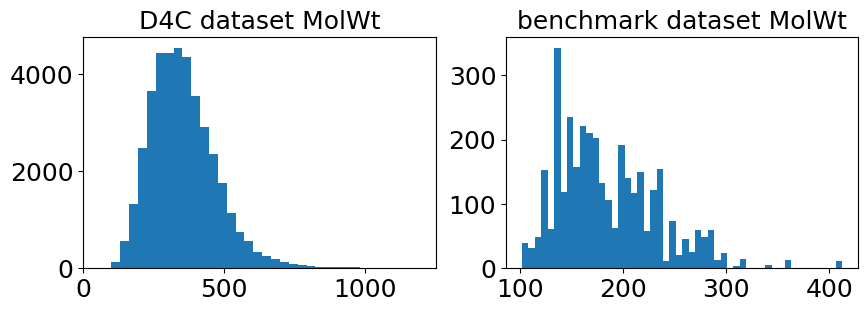

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
title = ['D4C dataset MolWt', 'benchmark dataset MolWt']
for i, dataset in enumerate([d4c, benchmark]):    
    molwt_list = [Descriptors.MolWt(Chem.MolFromSmiles(smiles)) for smiles in pd.Series(dataset['Smiles'])]
    if i==0: 
        bin_n = 100
    else:
        bin_n = 50
    axs[i%2].hist(molwt_list, bins=bin_n)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].tick_params(axis='x', labelsize=18)
    axs[i%2].tick_params(axis = 'y', labelsize=18)
    if i==0:
        axs[i%2].set_xlim(0,1250)
plt.show()

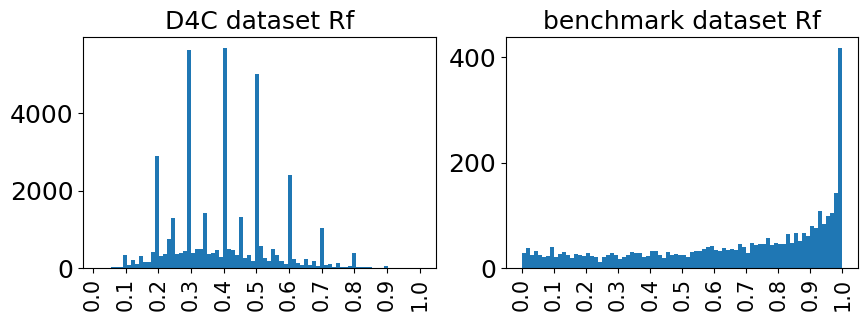

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
title = ['D4C dataset Rf', 'benchmark dataset Rf']
bin_n = 80
for i, dataset in enumerate([d4c, benchmark]):    

    axs[i%2].hist(dataset['Rf'], bins=bin_n)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].set_xticks(np.linspace(0,1,11))
    axs[i%2].tick_params(axis='x', labelsize=15, rotation =90 )
    axs[i%2].tick_params(axis = 'y', labelsize=18)

plt.show()

/tmp/ipykernel_218342/1842744870.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_218342/1842744870.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')


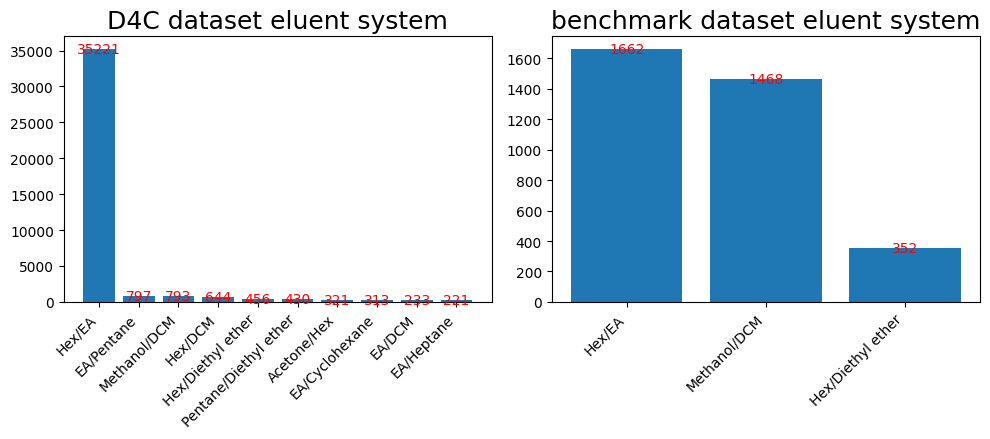

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
smiles2name_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['std_name']))

title = ['D4C dataset eluent system', 'benchmark dataset eluent system']
for i, dataset in enumerate([d4c, benchmark]):  
    elu_combi = [set([str(smiles2name_converter[dataset.iloc[i,1]]),str(smiles2name_converter[dataset.iloc[i,2]])]) for i in range(len(dataset))]
    elu_combi = [e.discard('nan') if 'nan' in e else e for e in elu_combi]
    elu_combi_count = pd.Series(elu_combi).value_counts()
    elu_combi_count = elu_combi_count[elu_combi_count>150]
    bi_sys = ['/'.join([list(sys)[0], list(sys)[1]]) for sys in elu_combi_count.index]

    axs[i%2].bar(bi_sys, elu_combi_count)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
    for ii, v in enumerate(elu_combi_count):
        axs[i%2].text(ii, v, str(v), ha='center', va='center', fontsize=10, color = 'red')

plt.tight_layout()
plt.show()


/tmp/ipykernel_218342/1983762268.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_218342/1983762268.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')


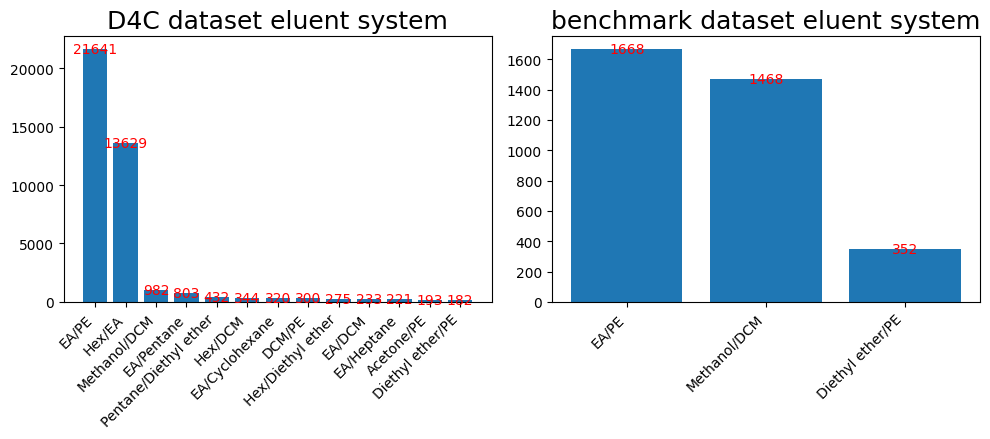

In [13]:
united_567 = pd.read_csv('./DB/collecting/filtered_data/united_567filtered.csv')
d4c_567 = united_567[united_567['DataSource'] == 'D4C']
benchmark_567 = united_567[united_567['DataSource'] == 'benchmark']

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
smiles2name_converter = dict(zip(elu_inform['567_Smiles'], elu_inform['std_name']))

title = ['D4C dataset eluent system', 'benchmark dataset eluent system']
for i, dataset in enumerate([d4c_567, benchmark_567]):  
    elu_combi = [set([str(smiles2name_converter[dataset.iloc[i,1]]),str(smiles2name_converter[dataset.iloc[i,2]])]) for i in range(len(dataset))]
    elu_combi = [e.discard('nan') if 'nan' in e else e for e in elu_combi]
    elu_combi_count = pd.Series(elu_combi).value_counts()
    elu_combi_count = elu_combi_count[elu_combi_count>150]
    bi_sys = ['/'.join([list(sys)[0], list(sys)[1]]) for sys in elu_combi_count.index]

    axs[i%2].bar(bi_sys, elu_combi_count)
    axs[i%2].set_title(title[i], fontsize=18)
    axs[i%2].set_xticklabels(bi_sys, rotation=45, ha='right')
    for ii, v in enumerate(elu_combi_count):
        axs[i%2].text(ii, v, str(v), ha='center', va='center', fontsize=10, color = 'red')

plt.tight_layout()
plt.show()

In [14]:
united

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,Br/C(=C\n1cc(-c2ccccc2)nn1)c1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.600000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
2,BrC#Cc1ccc(-n2c3ccccc3c3ccccc32)cc1,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.300000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
3,BrC#Cc1ccc(C#Cc2ccccc2)cc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.400000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC#Cc1ccc2c(c1)CC2,CCCCCC,CCOC(C)=O,0.986828,0.013172,0.700000,Q,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
...,...,...,...,...,...,...,...,...,...
43703,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
43704,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
43705,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
43706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


## 사용할 데이터만 추리기

In [14]:
from decimal import Decimal

def is_it_quantized(num):
    a = Decimal(str(num)) % Decimal("0.05") # 문자를 Decimal로 변환시킨 수를 사용해야 부동소수점 오차 안남.
    if a > 0:
        return False
    else:
        return True

def data_scoop(data_df):
    data_df_ = data_df.copy()
    print("C_paper (or data) / Q_data (or data) / D4C / benchmark / all 중 선택")
    w= input("C_paper (or data) / Q_data (or data) / D4C / benchmark / all 중 선택")
    if w == 'C_paper':
        s_data = data_df_[data_df_['Rf_type']=='C']
    elif w == 'C_data':
        q_mask = data_df_['Rf'].apply(is_it_quantized)
        s_data = data_df[~q_mask]

    elif w == 'Q_paper':
        s_data = data_df_[data_df_['Rf_type']=='Q']
    elif w == 'Q_data':
        s_data = data_df_[q_mask]

    elif w == 'D4C':
        s_data = data_df_[data_df_['DataSource'] =='D4C']
    elif w == 'benchmark':
        s_data = data_df_[data_df_['DataSource'] =='benchmark']

    elif w == 'all':
        s_data = data_df_
    else:
        print('뭐 쓸건지 제대로 고르시오! 잘못 골랐거나 안골랐음!')
        return 
    print(f'{w} 골랐음!')
    return s_data

In [15]:
'''united_ = data_scoop(united)
united_.reset_index(drop=True, inplace=True)
united_'''

united_ = data_scoop(united)
# test_data = data_scoop(united)

united_.reset_index(drop=True, inplace=True)
# test_data.reset_index(drop=True, inplace=True)

C_paper (or data) / Q_data (or data) / D4C / benchmark / all 중 선택
C_paper 골랐음!


# mean, variance update

In [17]:
"""#역sigmoid 라벨 사용
united_E = united_[united_['Rf']<1]
united_E.reset_index(drop=True, inplace=True)
united_E['Rf'] =  -np.log((1/united_E['Rf']) - 1)"""


/tmp/ipykernel_623054/1517872110.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  united_E['Rf'] =  -np.log((1/united_E['Rf']) - 1)


In [ ]:
"""united_ = united_E"""

In [16]:
united_

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers
1,BrC(Br)=Cn1c2ccccc2c2ccccc21,CCCCC,CCOC(C)=O,0.884089,0.115911,0.900000,C,D4C,average of several papers
2,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...
3,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...
4,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.450000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.5...
...,...,...,...,...,...,...,...,...,...
14706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark
14707,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark
14708,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark
14709,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark


In [18]:
# 여기선 평균, 표준편차만 저장하고 표준화는 graph만들면서 진행

def standardization(DB_df, columns_list, backup=False):
    # columns_list : list of prop

    mean = DB_df[columns_list].mean(axis=0)
    std = DB_df[columns_list].std(axis=0)
    if backup==True:
        np.save('standardization/backup/mean_backup.npy', np.array(mean, dtype = np.float32))
        np.save('standardization/backup/std_backup.npy', np.array(std, dtype = np.float32))
    else:
        np.save('standardization/mean.npy', np.array(mean, dtype = np.float32))
        np.save('standardization/std.npy', np.array(std, dtype = np.float32))
        
    return None


def inverse_standardization(pred_nd_array, mean, std):
    return pred_nd_array * std + mean


In [19]:
# 라벨의 평균, 분산 업데이트

standardization(united_, ['Rf'])

In [ ]:
'''# 라벨의 평균, 분산 backup 저장

standardization(united, ['Rf'], backup=True)'''

# Train/Valid split

In [ ]:
# mol 상관 없이 data point 기준으로 랜덤split
'''
from sklearn.model_selection import train_test_split

train_set, valid_set = train_test_split(united_, test_size=0.2, random_state=42, shuffle=True)
train_set = train_set.reset_index(drop=True)
valid_set = valid_set.reset_index(drop=True)

path_raw = './DB/Rf'
train_set.to_csv(path_raw + '/only_nat_train_randomsplit.csv', index=False)
valid_set.to_csv(path_raw + '/only_nat_valid_randomsplit.csv', index=False)

'''

"\nfrom sklearn.model_selection import train_test_split\n\ntrain_set, valid_set = train_test_split(united, test_size=0.2, random_state=42, shuffle=True)\ntrain_set = train_set.reset_index(drop=True)\nvalid_set = valid_set.reset_index(drop=True)\n\npath_raw = './DB/Rf'\ntrain_set.to_csv(path_raw + '/only_nat_train_randomsplit.csv', index=False)\nvalid_set.to_csv(path_raw + '/only_nat_valid_randomsplit.csv', index=False)\n\n"

In [19]:
# split 하기 전에, 나중에 학습 후 datapoint별 추적을 의한 sample_id 지정해두기
united_.loc[:,'sample_id'] = united_.index

d4c = united_[united_['DataSource'] == 'D4C']
benchmark = united_[united_['DataSource'] == 'benchmark']
print(f'd4c: {len(d4c)}개, benchmark: {len(benchmark)}개')

d4c: 11229개, benchmark: 3482개


In [20]:
def make_test_set_split_only_by_mol(data, test_ratio, random_state=42):

    mol_class = data["Smiles"].drop_duplicates()
    mol_train = mol_class.sample(frac=(1 - test_ratio), random_state=random_state)
    mol_test = mol_class.drop(index=mol_train.index)

    # 3. isin()으로 필터링 - concat 반복 제거
    train_set = data[data["Smiles"].isin(mol_train)].copy()
    test_set = data[data["Smiles"].isin(mol_test)].copy()
    
    # 4. 인덱스 정리
    train_set.reset_index(drop=True, inplace=True)
    test_set.reset_index(drop=True, inplace=True)

    return train_set, test_set


In [22]:

# d4c, nat data 에서 일정 비율로 train/valid 나눠서 일정 비율로 train/valid 구성

train_set1, valid_set1 = make_test_set_split_only_by_mol(d4c, 0.2)
valid_set1, test_set1 = make_test_set_split_only_by_mol(valid_set1, 0.5)

train_set2, valid_set2 = make_test_set_split_only_by_mol(benchmark, 0.2)
valid_set2, test_set2 = make_test_set_split_only_by_mol(valid_set2, 0.5)

train_set = pd.concat([train_set1, train_set2], axis=0).reset_index(drop=True)
valid_set = pd.concat([valid_set1, valid_set2], axis=0).reset_index(drop=True)
test_set = pd.concat([test_set1, test_set2], axis=0).reset_index(drop=True)


In [18]:
'''
# d4c, nat data 에서 일정 비율로 train/valid 나눠서 일정 비율로 train/valid 구성
# + D4c dataset 에서는 Q_paper data 만 추려서 valid set으로 넘김 (Q 가 오차 있는 데이터라면, 학습땐 손실함수 개선해서 사용하더라도, 검증에서는 빼줘야함)

print(f"d4c 내의 C_paper data 수 : {len(d4c[d4c['Rf_type']=='C'])}")
C_d4c = d4c[d4c['Rf_type']=='C']
Q_d4c = d4c[d4c['Rf_type']!='C']
C_d4c_train_set, C_d4c_valid_set = make_test_set_split_only_by_mol(C_d4c, 0.2)
benchmark_train_set, benchmark_valid_set = make_test_set_split_only_by_mol(benchmark, 0.2)

train_set = pd.concat([C_d4c_train_set, Q_d4c, benchmark_train_set], axis=0).reset_index(drop=True)
valid_set = pd.concat([C_d4c_valid_set, benchmark_valid_set], axis=0).reset_index(drop=True)
'''

'\n# d4c, nat data 에서 일정 비율로 train/valid 나눠서 일정 비율로 train/valid 구성\n# + D4c dataset 에서는 Q_paper data 만 추려서 valid set으로 넘김 (Q 가 오차 있는 데이터라면, 학습땐 손실함수 개선해서 사용하더라도, 검증에서는 빼줘야함)\n\nprint(f"d4c 내의 C_paper data 수 : {len(d4c[d4c[\'Rf_type\']==\'C\'])}")\nC_d4c = d4c[d4c[\'Rf_type\']==\'C\']\nQ_d4c = d4c[d4c[\'Rf_type\']!=\'C\']\nC_d4c_train_set, C_d4c_valid_set = make_test_set_split_only_by_mol(C_d4c, 0.2)\nbenchmark_train_set, benchmark_valid_set = make_test_set_split_only_by_mol(benchmark, 0.2)\n\ntrain_set = pd.concat([C_d4c_train_set, Q_d4c, benchmark_train_set], axis=0).reset_index(drop=True)\nvalid_set = pd.concat([C_d4c_valid_set, benchmark_valid_set], axis=0).reset_index(drop=True)\n'

In [23]:
path_raw = './DB/Rf'
train_set.to_csv(path_raw + '/United_DB_train.csv', index=False)
valid_set.to_csv(path_raw + '/United_DB_valid.csv', index=False)
test_set.to_csv(path_raw + '/United_DB_test.csv', index=False)

In [21]:
path_raw = './DB/Rf'
train_set = pd.read_csv(path_raw + '/United_DB_train.csv')
valid_set = pd.read_csv(path_raw + '/United_DB_valid.csv')
test_set = pd.read_csv(path_raw + '/United_DB_test.csv')
print(f'trainset: {len(train_set)}개 / validset: {len(valid_set)}개 / testset: {len(test_set)}개')

trainset: 11797개 / validset: 1440개 / testset: 1474개


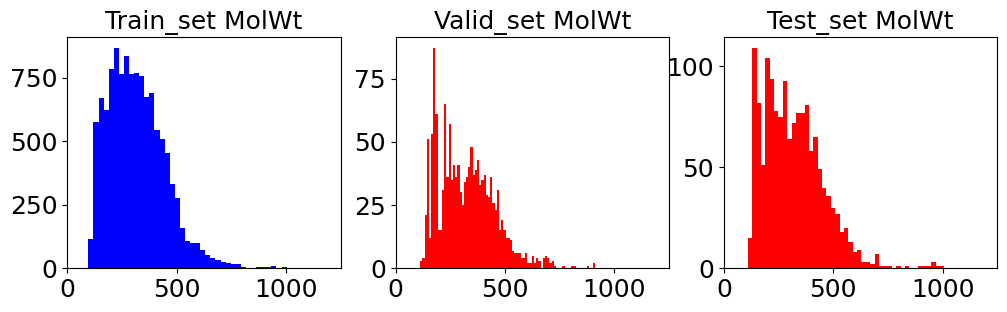

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
title = ['Train_set MolWt', 'Valid_set MolWt', 'Test_set MolWt']
bin_n = 80
for i, dataset in enumerate([train_set, valid_set, test_set]):    
    if i ==0:
        color = 'blue'
    elif i ==1:
        color = 'red'
    molwt_list = [Descriptors.MolWt(Chem.MolFromSmiles(smiles)) for smiles in pd.Series(dataset['Smiles'])]
    axs[i%3].hist(molwt_list, bins=bin_n, color = color)
    axs[i%3].set_title(title[i], fontsize=18)
    axs[i%3].tick_params(axis='x', labelsize=18)
    axs[i%3].tick_params(axis = 'y', labelsize=18)
    axs[i%3].set_xlim(0,1250)
plt.show()

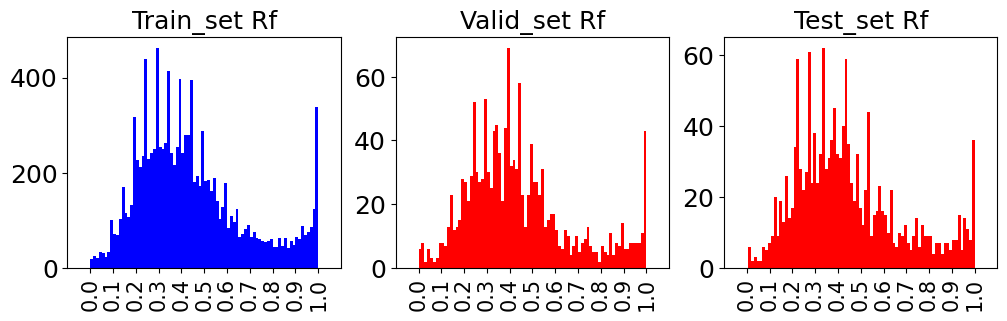

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
title = ['Train_set Rf', 'Valid_set Rf', 'Test_set Rf']
for i, dataset in enumerate([train_set, valid_set, test_set]):    
    if i ==0:
        color = 'blue'
    elif i ==1:
        color = 'red'
    axs[i%3].hist(dataset['Rf'], bins=80, color = color)
    axs[i%3].set_title(title[i], fontsize=18)
    axs[i%3].tick_params(axis='x', labelsize=15, rotation =90 )
    axs[i%3].tick_params(axis = 'y', labelsize=18)

    # axs[i%3].set_xlim(-0.1,1.1)
    # axs[i%3].set_xticks(np.linspace(0,1,11)) 

    axs[i%3].set_xlim(-0.1,1.1)
    axs[i%3].set_xticks(np.linspace(0,1,11))

plt.show()

/tmp/ipykernel_1274712/3030956997.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_1274712/3030956997.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')
/tmp/ipykernel_1274712/3030956997.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')


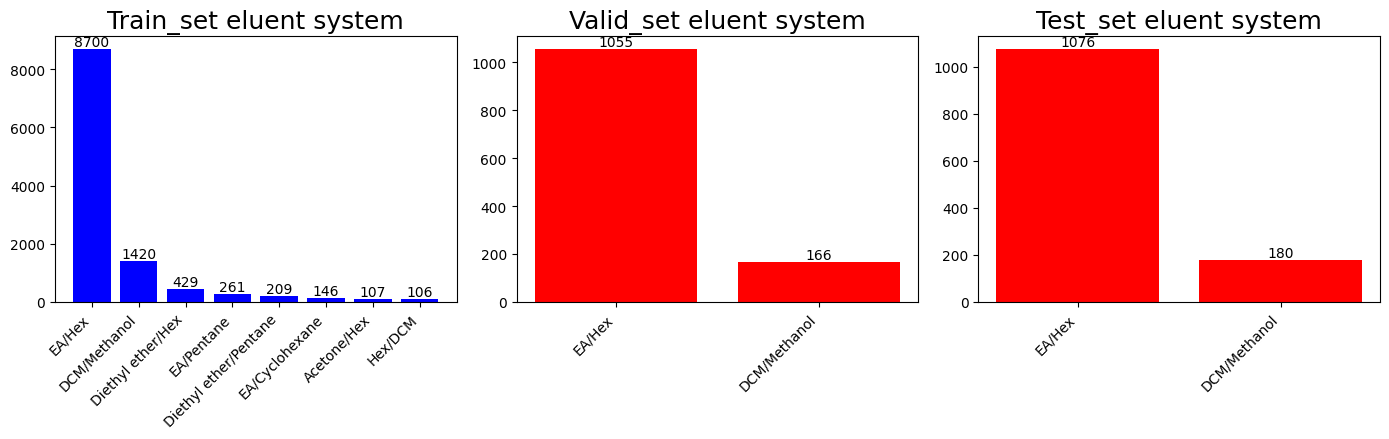

In [19]:
elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
smiles2name_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['std_name']))

fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))

title = ['Train_set eluent system', 'Valid_set eluent system', 'Test_set eluent system']
for i, dataset in enumerate([train_set, valid_set, test_set]):  
    if i ==0:
        color = 'blue'
    elif i ==1:
        color = 'red'
    elu_combi = [set([str(smiles2name_converter[dataset.iloc[i,1]]),str(smiles2name_converter[dataset.iloc[i,2]])]) for i in range(len(dataset))]
    elu_combi = [a.discard('nan') if 'nan' in e else e for e in elu_combi]
    elu_combi_count = pd.Series(elu_combi).value_counts()
    elu_combi_count = elu_combi_count[elu_combi_count>100]
    bi_sys = ['/'.join([list(sys)[0], list(sys)[1]]) for sys in elu_combi_count.index]

    axs[i%3].bar(bi_sys, elu_combi_count, color = color)
    axs[i%3].set_title(title[i], fontsize=18)
    axs[i%3].set_xticklabels(bi_sys, rotation=45, ha='right')
    for ii, v in enumerate(elu_combi_count):
        axs[i%3].text(ii, v, str(v), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Make graph

In [22]:
# Rf 라벨 사용
# 이건 set 별로 따로 저장 안 해놓으니까 set 바꿀 때마다 '''기존 그래프 셋 지우고''' 새로 만들기 잊지 말자

from make_graph_dataloader import MolToGraph

path_raw = './DB/Rf'
compound_train_set = MolToGraph('Smiles', path_raw, 'United_DB_train.csv', 'compound_train.pt', molecular_param = False)
compound_valid_set = MolToGraph('Smiles', path_raw, 'United_DB_valid.csv', 'compound_valid.pt', molecular_param = False)
compound_test_set = MolToGraph('Smiles', path_raw, 'United_DB_test.csv', 'compound_test.pt', molecular_param = False)

elu1_train_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_train.csv', 'elu1_train.pt', molecular_param = False)
elu1_valid_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_valid.csv', 'elu1_valid.pt', molecular_param = False)
elu1_test_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_test.csv', 'elu1_test.pt', molecular_param = False)

elu2_train_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_train.csv', 'elu2_train.pt', molecular_param = False)
elu2_valid_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_valid.csv', 'elu2_valid.pt', molecular_param = False)
elu2_test_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_test.csv', 'elu2_test.pt', molecular_param = False)

In [ ]:
# 역 sigmoid 라벨 사용한 graph 만들기

from make_graph_dataloader import MolToGraph

path_raw = './DB/Rf'
compound_train_set = MolToGraph('Smiles', path_raw, 'United_DB_train.csv', 'sigmoid/compound_train.pt', molecular_param = False)
compound_valid_set = MolToGraph('Smiles', path_raw, 'United_DB_valid.csv', 'sigmoid/compound_valid.pt', molecular_param = False)
compound_test_set = MolToGraph('Smiles', path_raw, 'United_DB_test.csv', 'sigmoid/compound_test.pt', molecular_param = False)

elu1_train_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_train.csv', 'sigmoid/elu1_train.pt', molecular_param = False)
elu1_valid_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_valid.csv', 'sigmoid/elu1_valid.pt', molecular_param = False)
elu1_test_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_test.csv', 'sigmoid/elu1_test.pt', molecular_param = False)

elu2_train_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_train.csv', 'sigmoid/elu2_train.pt', molecular_param = False)
elu2_valid_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_valid.csv', 'sigmoid/elu2_valid.pt', molecular_param = False)
elu2_test_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_test.csv', 'sigmoid/elu2_test.pt', molecular_param = False)

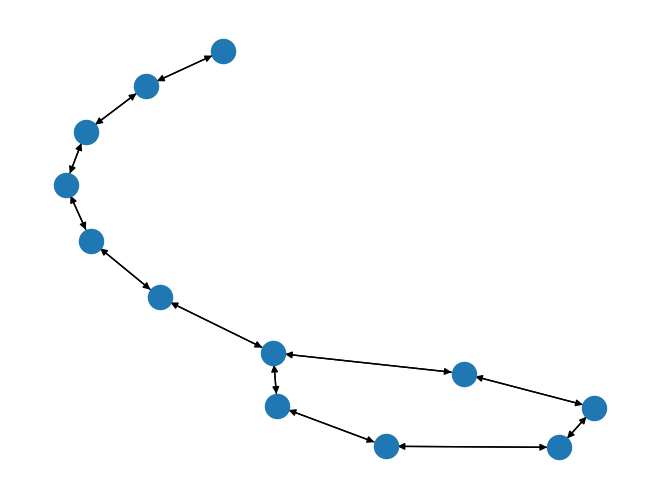

In [19]:
from torch_geometric.utils import to_networkx
from networkx import draw
g = to_networkx(compound_train_set[1])
draw(g)

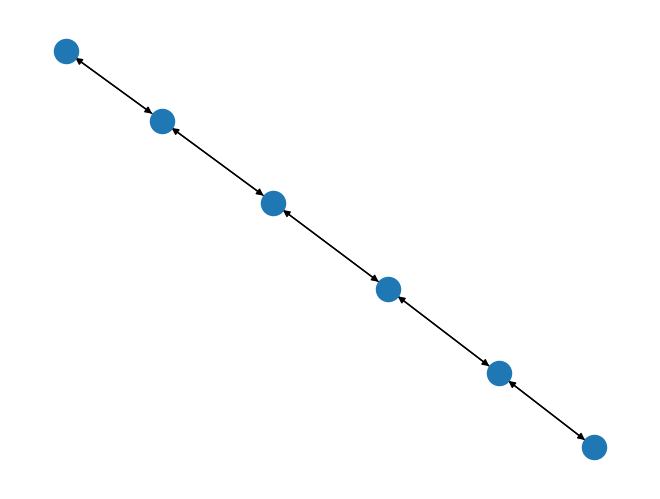

In [23]:
from torch_geometric.utils import to_networkx
from networkx import draw
g = to_networkx(elu1_train_set[1])
draw(g)

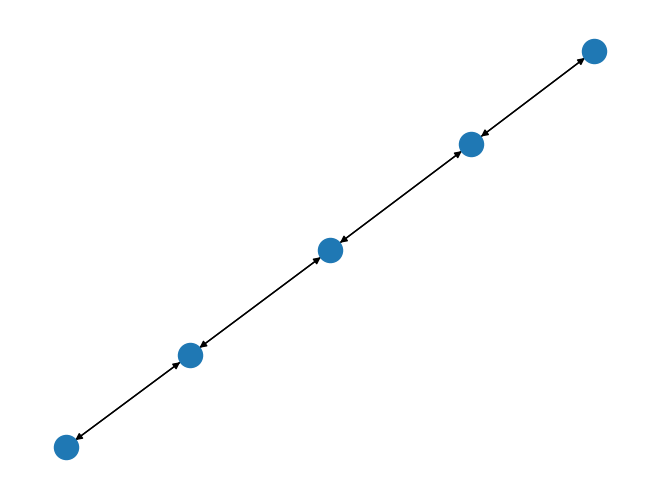

In [24]:
from torch_geometric.utils import to_networkx
from networkx import draw
g = to_networkx(elu2_train_set[1])
draw(g)

## dataloader
#### batch_size는 흔히 하는 그 batch의 크기 : 데이터 샘플의 개수

In [23]:
from make_graph_dataloader import TripleGraphDataset

graph_train_set = TripleGraphDataset(
    compound_train_set,
    elu1_train_set,
    elu2_train_set
)
graph_valid_set = TripleGraphDataset(
    compound_valid_set,
    elu1_valid_set,
    elu2_valid_set
)
graph_test_set = TripleGraphDataset(
    compound_test_set,
    elu1_test_set,
    elu2_test_set
)
train_loader = DataLoader(graph_train_set, batch_size=500, shuffle=True)
valid_loader = DataLoader(graph_valid_set, batch_size =500, shuffle=True)
test_loader = DataLoader(graph_test_set, batch_size =500, shuffle=True)

In [28]:
train_iter = iter(train_loader)
next(train_iter)


[DataBatch(x=[11089, 48], edge_index=[2, 23660], edge_attr=[23660, 1], y=[500, 1], ratio=[500, 2], sample_id=[500, 1], batch=[11089], ptr=[501]),
 DataBatch(x=[2811, 48], edge_index=[2, 4640], edge_attr=[4640, 1], y=[500, 1], ratio=[500, 2], sample_id=[500, 1], batch=[2811], ptr=[501]),
 DataBatch(x=[2728, 48], edge_index=[2, 4456], edge_attr=[4456, 1], y=[500, 1], ratio=[500, 2], sample_id=[500, 1], batch=[2728], ptr=[501])]

In [29]:
train_iter = iter(train_loader)
a= next(train_iter)[0].y

(array([ 14.,  58., 100.,  99.,  89.,  38.,  21.,  24.,  19.,  38.]),
 array([-1.82199275, -1.40196705, -0.98194128, -0.56191552, -0.14188978,
         0.27813596,  0.69816172,  1.11818743,  1.53821313,  1.95823896,
         2.37826467]),
 <BarContainer object of 10 artists>)

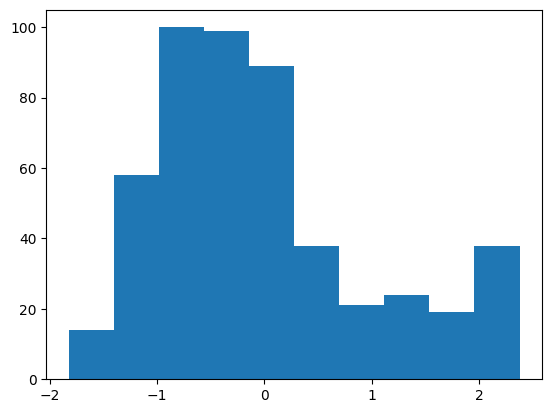

In [30]:
plt.hist(a)

## MODEL

In [49]:
#DMPNN
from DMPNN_model_architecture import DMPNN_eluent_interaction_5 as DMPNN_model_5
from DMPNN_model_architecture import DMPNN_eluent_interaction_3 as DMPNN_model_3
#GAT
from GAT_model_architecture import GAT_eluent_interaction_5 as GAT_model_5
from GAT_model_architecture import GAT_eluent_interaction_3 as GAT_model_3
#GCN
from model_architecture import GCN_eluent_interaction_5 as model_5
from model_architecture import GCN_eluent_interaction_3 as model_3

#from model_architecture import GCN_eluent_interaction_7_light as model_7_light

# Run

In [25]:
# simle one

class CallBack():
    def __init__(self, patience=20, delta=0.0, optimal_path='./ckpt/opt_checkpoint.pt', last_path = './ckpt/last_ckpt.pt'):
        self.patience = patience
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.delta = delta
        self.opt_path = optimal_path
        self.last_path = last_path

    def __call__(self, epoch, model, optimizer, scheduler, train_loss, train_r2, valid_loss, valid_r2):
        
        # save last checkpoint
        self.save_last_checkpoint(epoch, model, optimizer, scheduler, train_loss, train_r2, valid_loss, valid_r2)

        # save optimal checkpoint
        score = valid_loss[-1]
        if self.best_score is None:
            self.best_score = score
            self.save_optimal_checkpoint(epoch, model, train_loss, train_r2, valid_loss, valid_r2)
        elif score >= self.best_score - self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_optimal_checkpoint(epoch, model, train_loss, train_r2, valid_loss, valid_r2)
            self.counter = 0

        return self.early_stop

    def save_optimal_checkpoint(self, epoch, model, train_loss, train_r2, valid_loss, valid_r2):

        # 저장 중간에 학습 중단하면 파일 깨져버리기 때문에 임시파일에 저장 먼저 함
        # 저장 중 중단되면 temp_path는 손상되지만, os.replace 과정에서 정상 저장된 파일 까지만 save_path로 교체
        
        temp_path = self.opt_path + '.tmp'  
        torch.save({'epoch' : epoch,
                    'model_state_dict' : model.state_dict(),
                    'train_loss' :train_loss[-1],
                    'train_r2' :train_r2[-1],
                    'valid_loss' : valid_loss[-1],
                    'valid_r2' :valid_r2[-1]},
                  temp_path)
        os.replace(temp_path, self.opt_path)

    def save_last_checkpoint(self, epoch, model, opt, sch, train_loss, train_r2, valid_loss, valid_r2):
        temp_path = self.last_path + '.tmp'
        torch.save({'epoch': epoch,
                   'model_state_dict' : model.state_dict(),
                   'optimizer_state_dict' : opt.state_dict(),
                   'scheduler_state_dict' : sch.state_dict(),
                   'train_loss' : train_loss,
                   'train_r2' :train_r2,
                   'valid_loss' : valid_loss,
                   'valid_r2' :valid_r2},
                  temp_path)
        os.replace(temp_path, self.last_path)

In [26]:
# loss_functions

def custom_mae_loss(output, label, purpose = 'train'):

    output = output[0] if isinstance(output, (tuple, list)) else output
    output = output.reshape(label.shape)
    
    nan_mask = ~torch.isnan(label)
    if purpose == 'train':
        std_mae = torch.mean(torch.abs(output[nan_mask]-label[nan_mask]))
        return std_mae


    elif purpose == 'lookup':
        real_output = inverse_standardization(output, mean, std)
        real_label = inverse_standardization(label, mean, std)
        real_mae = torch.mean(torch.abs(real_output[nan_mask]-real_label[nan_mask]))
        return real_mae

In [ ]:
# 라벨에 따른 가중치 적용된 loss

def r2_score(preds, targets):
    mean = torch.sum(targets)/len(targets)
    ss_res = torch.sum((targets - preds) ** 2)
    ss_tot = torch.sum((targets - mean) ** 2)
    return 1- ss_res / ss_tot 

SCALE = 100  # 소수 n자리까지 보겠다

y_train = train_set["Rf"].values.astype(np.float32)  # (N,)
y_train = y_train[~np.isnan(y_train)]  # 안전용

# 1) 정수 그리드로 올리기: 0.1234 -> 1234
y_code = np.round(y_train * SCALE).astype(np.int64)   # (N,)

max_code = y_code.max()
freq_table = np.bincount(y_code, minlength=max_code + 1)  # freq_table[code] = 빈도

# 2) torch tensor로 변환 (나중에 GPU로도 올려서 씀)
label_counts = torch.tensor(freq_table, dtype=torch.float32)   # (max_code+1,)



def make_weights_scalar(y, label_counts, alpha, eps=1e-3):
    SCALE = 10000  # 위와 동일하게
    """
    y: (batch,) float tensor, 예: Rf ∈ [0,1]
    label_counts: (max_code+1,) 각 정수 코드별 빈도
    """
    # (예측값 말고)라벨을 정수 코드로 올리기
    y_code = torch.round(y * SCALE).long()           # (batch,)
    y_code = y_code.clamp(min=0, max=label_counts.numel()-1)

    # 2) 해당 코드의 등장 빈도 가져오기
    freq = label_counts[y_code]                     # (batch,)

    # 3) 라벨(예측 말고) 빈도가 클수록 weight 작게
    w = (1.0 / (freq + eps)) ** alpha

    # 4) 전체 스케일 맞추기 (loss 크기 지나치게 줄어드는 거 방지)
    w = w / w.mean()
    return w


def weighted_mse_loss(y_pred, y, label_counts, alpha=0.25):
    
    y_pred = y_pred.reshape(y.shape)
    nan_mask = ~torch.isnan(y)

    real_output = inverse_standardization(y_pred[nan_mask], mean, std)
    real_label = inverse_standardization(y[nan_mask], mean, std)
    
    # 가중치 구할떄, label_count에서 라벨 개수 올바르게 불러내려면, 정규화 안된 진짜 라벨 써야함
    w = make_weights_scalar(real_label.detach(), label_counts, alpha)

    # mse
    loss = torch.mean(w*(y_pred[nan_mask] - y[nan_mask])**2)
    
    # mae
    #loss = torch.mean(w * torch.abs(y_pred[nan_mask] - y[nan_mask]))

    real_mae = torch.mean(torch.abs(real_output-real_label)) # 가중치 없고 , 정규화 풀은 MAE

    r2 = r2_score(real_output, real_label)
 
    return loss, real_mae, r2



In [36]:
# sigmoid loss
def r2_score(preds, targets):
    mean = torch.sum(targets)/len(targets)
    ss_res = torch.sum((targets - preds) ** 2)
    ss_tot = torch.sum((targets - mean) ** 2)
    return 1- ss_res / ss_tot 

# sigmoid loss - 근데 이제 모든 데이터에 적용
def sigmoid_weight_mse(y_pred, y, eps=0.05, tau=0.003):
    y_pred = y_pred.reshape(y.shape)
    nan_mask = ~torch.isnan(y)
    abs_diff = torch.abs(y_pred[nan_mask] - y[nan_mask])

    # 가중치 구할때도, 정규화 안된 진짜 라벨 써야함
    real_output = inverse_standardization(y_pred[nan_mask], mean, std).detach()
    real_label = inverse_standardization(y[nan_mask], mean, std).detach()
    real_abs_diff = torch.abs(real_output - real_label)
    w = torch.sigmoid((real_abs_diff - eps) / tau)
    loss = torch.mean(w * abs_diff**2) # mse 사용

    # 로그용 mae
    real_mae = torch.mean(abs_diff) # 가중치 없고 , 정규화 풀은 MAE
    # 로그용 R2
    r2 = r2_score(real_output, real_label)
    return loss, real_mae, r2


# sigmoid loss - C_Rf, Q_Rf 둘다에게 전용으로 적용
def sigmoid_weight_mse_for_CQ(y_pred, y, eps_C =0.015 , eps_Q=0.05, tau_C=0.001 ,tau_Q=0.001):
    y_pred = y_pred.reshape(y.shape)
    nan_mask = ~torch.isnan(y)

    abs_diff = torch.abs(y_pred[nan_mask] - y[nan_mask])

    # 역정규화된 진짜 Rf
    real_output = inverse_standardization(y_pred[nan_mask], mean, std).detach()
    real_label  = inverse_standardization(y[nan_mask], mean, std).detach()
    real_abs_diff = torch.abs(real_output - real_label)

    ################ Q_Rf (0.1, 0.2, ... 0.9) 판별##############

    tol = 1e-6  # 부동소수 오차 허용치

    scaled  = torch.round(real_label * 10.0)     
    rounded = scaled / 10.0                      
    mask_close = torch.abs(real_label - rounded) < tol # 역 표준화 할때 부동 소수점 불일치 생길수 있어서
    mask_range = (scaled >= 1) & (scaled <= 9)    
    mask_Q = mask_close & mask_range        

    ################# sigmoid weight #####################
    C_w = torch.sigmoid((real_abs_diff - eps_C) / tau_C)
    Q_w = torch.sigmoid((real_abs_diff - eps_Q) / tau_Q)

    # Q_Rf 에만 Q_w, C_w 각각 적용
    w = torch.ones_like(C_w)
    w[~mask_Q] = C_w[~mask_Q]
    w[mask_Q] = Q_w[mask_Q]

    loss = torch.mean(w * (abs_diff**2)) # MSE 사용

    # 로그용
    real_mae = torch.mean(real_abs_diff)
    r2 = r2_score(real_output, real_label)

    return loss, real_mae, r2

    
# sigmoid loss - Q_Rf에만 적용
def sigmoid_weight_mse_for_Q(y_pred, y, eps=0.1, tau=0.005):
    y_pred = y_pred.reshape(y.shape)
    nan_mask = ~torch.isnan(y)

    abs_diff = torch.abs(y_pred[nan_mask] - y[nan_mask])

    # 역정규화된 진짜 Rf
    real_output = inverse_standardization(y_pred[nan_mask], mean, std).detach()
    real_label  = inverse_standardization(y[nan_mask], mean, std).detach()
    real_abs_diff = torch.abs(real_output - real_label)

    ################ Q_Rf (0.1, 0.2, ... 0.9) 판별##############

    tol = 1e-6  # 부동소수 오차 허용치

    scaled  = torch.round(real_label * 10.0)     
    rounded = scaled / 10.0                      
    mask_close = torch.abs(real_label - rounded) < tol # 역 표준화 할때 부동 소수점 불일치 생길수 있어서
    mask_range = (scaled >= 1) & (scaled <= 9)    
    mask_Q = mask_close & mask_range        

    ################# sigmoid weight #####################
    base_w = torch.sigmoid((real_abs_diff - eps) / tau)

    # Q_Rf 에만 base_w 적용, 아니면 w=1
    w = torch.ones_like(base_w)
    w[mask_Q] = base_w[mask_Q]

    loss = torch.mean(w * (abs_diff**2)) # MSE 사용

    # 로그용
    real_mae = torch.mean(real_abs_diff)
    r2 = r2_score(real_output, real_label)

    return loss, real_mae, r2


In [36]:
# simple run


from tqdm.auto import tqdm

path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_DMPNNmodel5_dropout0.3'
os.makedirs(path, exist_ok=False)
last_ckpt_path =  path + '/last_ckpt.pt'
optimal_ckpt_path = path + '/opt_checkpoint.pt'

read_me_path = path + '/about_this_model.txt'
arc = input('which version of model?')
about_data = input('used data / how to split train_test? (no dup data? or no dup mol?)')
pe = input('how to handle PE?')
pooling = input('how to pool context GCN vector?')
etc = input('anyting else to notice')
with open(read_me_path, 'a') as f:
    f.write(f'Model : {arc}\nAbout data : {about_data}\nPE : {pe}\nPooling : {pooling}\netc : {etc}')


device = torch.device('cuda')
model = DMPNN_eluent_interaction_5(dropout=0.3).to(device)
# model = DMPNN_eluent_interaction_3(dropout=0.3).to(device)
# model = GAT_model_5(dropout=0.3).to(device)
# model = GAT_model_3(dropout=0.3).to(device
# model = model_5(dropout=0.3).to(device)
# model = model_3(dropout=0.3).to(device)

loss_fn = custom_mae_loss
# loss_fn = gaussian_nll_loss_torch
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = 50, gamma= 1-0.015)
callback = CallBack(patience = 300, optimal_path = optimal_ckpt_path, last_path = last_ckpt_path)

# loss normalize
mean = torch.tensor(np.load('standardization/mean.npy')).to(device)
std = torch.tensor(np.load('standardization/std.npy')).to(device)



# class : run model
from Run_model import Run_deep_Rf
model_deep_Rf = Run_deep_Rf(device=device, relay = False,
                                      model = model,
                                      loss_fn = loss_fn,
                                      optimizer = optimizer,
                                      scheduler = scheduler,
                                      callback = callback,
                                      last_ckpt_path = last_ckpt_path,
                                      total_epoch = 10000)

In [ ]:
# simple run _ sigmoid loss


from tqdm.auto import tqdm

path = './ckpt(CQ_sigmoid_loss)(cluster_n=0.1, 0.05)_United_DB_model5'
os.makedirs(path, exist_ok=False)
last_ckpt_path =  path + '/last_ckpt.pt'
optimal_ckpt_path = path + '/opt_checkpoint.pt'

read_me_path = path + '/about_this_model.txt'
arc = input('which version of model?')
about_data = input('used data / how to split train_test? (no dup data? or no dup mol?)')
pe = input('how to handle PE?')
pooling = input('how to pool context GCN vector?')
etc = input('anyting else to notice')
with open(read_me_path, 'a') as f:
    f.write(f'Model : {arc}\nAbout data : {about_data}\nPE : {pe}\nPooling : {pooling}\netc : {etc}')


device = torch.device('cuda')
# model = model_7_light(version = 'only_interaction').to(device)
model = model_5().to(device)
loss_fn1 = sigmoid_weight_mse_for_CQ
loss_fn2 = sigmoid_weight_mse_for_CQ
######## for unbalance loss ###############
# label_counts = label_counts.to(device)
#####################################
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = 50, gamma= 1-0.015)
callback = CallBack(patience = 300, optimal_path = optimal_ckpt_path, last_path = last_ckpt_path)

# loss normalize
mean = torch.tensor(np.load('standardization/mean.npy')).to(device)
std = torch.tensor(np.load('standardization/std.npy')).to(device)



# class : run model
from Run_model import Run_deep_Rf_sigmoid
model_deep_Rf = Run_deep_Rf_sigmoid(device=device, relay = False,
                                      model = model,
                                      loss_fn1 = loss_fn1,
                                      #label_counts = label_counts,
                                      loss_fn2 = loss_fn2,
                                      optimizer = optimizer,
                                      scheduler = scheduler,
                                      callback = callback,
                                      last_ckpt_path = last_ckpt_path,
                                      total_epoch = 10000)

In [45]:
path

'ckpt_paper/ckpt_<C_paper_final>_<tvt>_DMPNNmodel5_dropout0.3'

In [38]:
model_deep_Rf(train_loader, valid_loader)

  0%|          | 0/10000 [00:00<?, ?it/s]

Epoch : 1 | Train_loss : 0.1960, Train_r2 : -0.4389 | Valid_loss : 0.1480, Valid_r2 : 0.3154
Epoch : 2 | Train_loss : 0.1371, Train_r2 : 0.4191 | Valid_loss : 0.1257, Valid_r2 : 0.4488
Epoch : 3 | Train_loss : 0.1270, Train_r2 : 0.4933 | Valid_loss : 0.1308, Valid_r2 : 0.4387
Epoch : 4 | Train_loss : 0.1195, Train_r2 : 0.5483 | Valid_loss : 0.1315, Valid_r2 : 0.4381
Epoch : 5 | Train_loss : 0.1165, Train_r2 : 0.5747 | Valid_loss : 0.1171, Valid_r2 : 0.5040
Epoch : 6 | Train_loss : 0.1120, Train_r2 : 0.5969 | Valid_loss : 0.1144, Valid_r2 : 0.5602
Epoch : 7 | Train_loss : 0.1061, Train_r2 : 0.6400 | Valid_loss : 0.1358, Valid_r2 : 0.4175
Epoch : 8 | Train_loss : 0.1064, Train_r2 : 0.6385 | Valid_loss : 0.1183, Valid_r2 : 0.5247
Epoch : 9 | Train_loss : 0.1004, Train_r2 : 0.6708 | Valid_loss : 0.1202, Valid_r2 : 0.5256
Epoch : 10 | Train_loss : 0.0968, Train_r2 : 0.6897 | Valid_loss : 0.1045, Valid_r2 : 0.6234
Epoch : 11 | Train_loss : 0.0941, Train_r2 : 0.7068 | Valid_loss : 0.1171, Val

In [40]:
path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_DMPNNmodel5_dropout0.3'

In [41]:
a= torch.load(path + '/opt_checkpoint.pt')

print(a['epoch'],a['train_loss'], a['train_r2'], a['valid_loss'], a['valid_r2'])

2010 0.025564661249518394 0.9776679873466492 0.07550361752510071 0.776179313659668


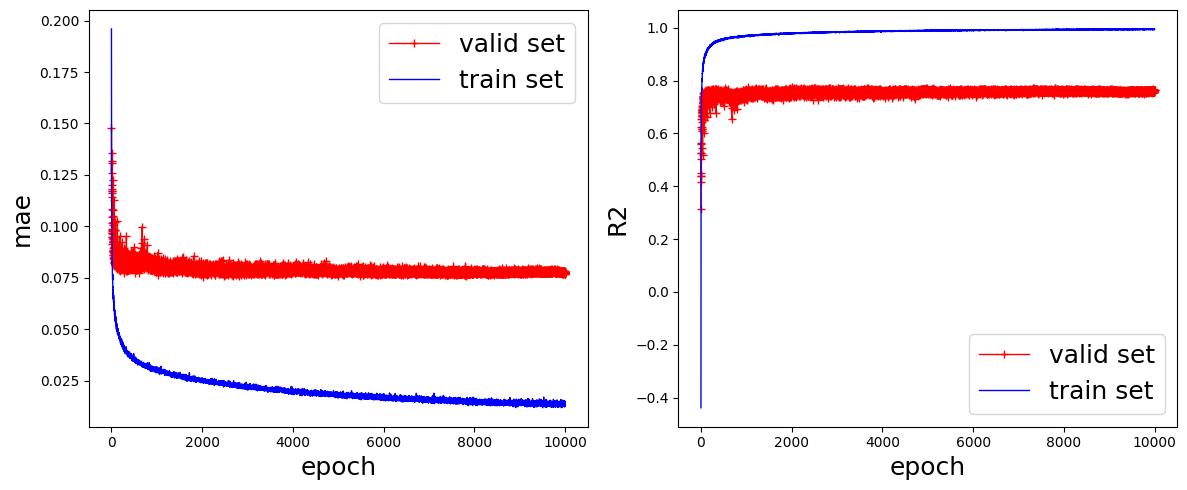

In [42]:
last_ckpt_path = path + '/last_ckpt.pt'
last_ckpt = torch.load(last_ckpt_path)

error_log_train = last_ckpt['train_loss']
r2_log_train = last_ckpt['train_r2']
error_log_valid = last_ckpt['valid_loss']
r2_log_valid = last_ckpt['valid_r2'] 


import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(error_log_valid, "r-+", linewidth=1, label='valid set')
axs[0].plot(error_log_train, "b-", linewidth=1, label='train set')
axs[0].set_xlabel('epoch', fontsize=18)
axs[0].set_ylabel('mae', fontsize=18)
axs[0].legend(loc='upper right', fontsize=18)

axs[1].plot(r2_log_valid, "r-+", linewidth=1, label='valid set')
axs[1].plot(r2_log_train, "b-", linewidth=1, label='train set')
axs[1].set_xlabel('epoch', fontsize=18)
axs[1].set_ylabel('R2', fontsize=18)
#axs[1].set_ylim(0, 1)
axs[1].legend(loc='lower right', fontsize=18)
#axs[1].set_ylim(-0.5, 1)


plt.tight_layout()  # tight_layout을 plt.show() 전에 호출하여 레이아웃 조정
plt.show()

## 중단된 학습 이어서 학습하기 (option)

In [52]:
path

'ckpt_paper/ckpt_<C_paper_final>_<tvt>_model5'

In [53]:
# 중단된 학습 이어서 학습하기

from tqdm.notebook import tqdm

last_ckpt_path = path + '/last_ckpt.pt'
optimal_ckpt_path = path + '/opt_checkpoint.pt'


device = torch.device('cuda')
model = model_5().to(device)
loss_fn = custom_mae_loss
# loss_fn1 = sigmoid_weight_mse_for_CQ
# loss_fn2 = sigmoid_weight_mse_for_CQ
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001, weight_decay = 5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size = 50, gamma= 1-0.015)
callback = CallBack(patience = 300, optimal_path = optimal_ckpt_path, last_path = last_ckpt_path)


# loss normalize
mean = torch.tensor(np.load('standardization/mean.npy')).to(device)
std = torch.tensor(np.load('standardization/std.npy')).to(device)


# class : run model
from Run_model import Run_deep_Rf as relay_run
model_deep_Rf_relay = relay_run(device=device, relay = True,
                                      model = model,
                                      loss_fn = loss_fn,
                                      optimizer = optimizer,
                                      scheduler = scheduler,
                                      callback = callback,
                                      last_ckpt_path = last_ckpt_path,
                                      total_epoch = 10000)

model_deep_Rf_relay(train_loader,valid_loader)

  0%|          | 0/2316 [00:00<?, ?it/s]

Epoch : 7685 | Train_loss : 0.0119, Train_r2 : 0.9954 | Valid_loss : 0.0770, Valid_r2 : 0.7671
Epoch : 7686 | Train_loss : 0.0124, Train_r2 : 0.9951 | Valid_loss : 0.0754, Valid_r2 : 0.7756
Epoch : 7687 | Train_loss : 0.0142, Train_r2 : 0.9934 | Valid_loss : 0.0768, Valid_r2 : 0.7671
Epoch : 7688 | Train_loss : 0.0136, Train_r2 : 0.9941 | Valid_loss : 0.0761, Valid_r2 : 0.7712
Epoch : 7689 | Train_loss : 0.0117, Train_r2 : 0.9955 | Valid_loss : 0.0764, Valid_r2 : 0.7694
Epoch : 7690 | Train_loss : 0.0128, Train_r2 : 0.9947 | Valid_loss : 0.0761, Valid_r2 : 0.7731
Epoch : 7691 | Train_loss : 0.0120, Train_r2 : 0.9952 | Valid_loss : 0.0770, Valid_r2 : 0.7662
Epoch : 7692 | Train_loss : 0.0146, Train_r2 : 0.9926 | Valid_loss : 0.0768, Valid_r2 : 0.7683
Epoch : 7693 | Train_loss : 0.0129, Train_r2 : 0.9945 | Valid_loss : 0.0770, Valid_r2 : 0.7663
Epoch : 7694 | Train_loss : 0.0131, Train_r2 : 0.9944 | Valid_loss : 0.0760, Valid_r2 : 0.7714
Epoch : 7695 | Train_loss : 0.0127, Train_r2 : 0.9

## model 불러오기

In [46]:
path = 'ckpt_paper/ckpt_<C_paper_final>_<tvt>_DMPNNmodel5_dropout0.3'

In [50]:
# 일반적인 모델 불러오기
train_loader = DataLoader(graph_train_set, batch_size=500, shuffle=True)
valid_loader = DataLoader(graph_valid_set, batch_size =500, shuffle=True)
test_loader = DataLoader(graph_test_set, batch_size =500, shuffle=True)


opt_ckpt = torch.load((path + '/opt_checkpoint.pt'))


############### penalty 모델 불러오기 ######################
#########################################################
'''
start_p 전의 opt model 불러오기
opt_ckpt = torch.load('./ckpt_only_d4c_model_5s_8_penalty_by_aug_start=1000/opt_checkpoint.pt')

start_p 이후의 opt model 불러오기
opt_ckpt = torch.load('./ckpt_only_d4c_model_5s_8_penalty_by_aug_start=1000/real_opt_ckpt.pt')

start_p 이후 마지막 last model 불러오기
opt_ckpt = torch.load(('./ckpt_only_d4c_model_5s_8_penalty_by_aug_start=1000/last_ckpt.pt'))
'''
#########################################################
#########################################################

device = torch.device('cuda')
model = DMPNN_model_5(dropout=0.3).to(device)
# model = DMPNN_model_3(dropout=0.3).to(device
# model = GAT_model_5(dropout=0.3).to(device)
# model = GAT_model_3(dropout=0.3).to(device
# model = model_5(dropout=0.3).to(device)
# model = model_3(dropout=0.3).to(device)
model.load_state_dict(opt_ckpt['model_state_dict'])


mean = np.load('./standardization/mean.npy')
std = np.load('./standardization/std.npy')

#train
train_pred=[]
train_label=[]
train_id = []
model.eval()
with torch.no_grad(): 
    for com, elu1, elu2 in train_loader:
        train_label.append(com.y)
        train_id.append(com.sample_id)
        com_train_batch = com.to(device)
        elu1_train_batch = elu1.to(device)
        elu2_train_batch = elu2.to(device)
        pred = model(com_train_batch, elu1_train_batch, elu2_train_batch)
        train_pred.append(pred.cpu())

train_label = np.vstack(train_label)
train_label = inverse_standardization(train_label, mean, std)
train_label= train_label[:, 0].reshape(-1,1)
mask = ~np.isnan(train_label)
train_label=train_label[mask]

train_pred = np.vstack(train_pred)
train_pred = inverse_standardization(train_pred, mean, std)
train_pred = train_pred.reshape(-1,1)
train_pred=train_pred[mask]


# valid
valid_pred=[]
valid_label=[]
valid_id=[]
model.eval()
with torch.no_grad():
    for com_val, elu1_val, elu2_val in valid_loader:
        valid_label.append(com_val.y)
        valid_id.append(com_val.sample_id)
        com_valid_batch = com_val.to(device)
        elu1_valid_batch = elu1_val.to(device)
        elu2_valid_batch = elu2_val.to(device)
        pred = model(com_valid_batch, elu1_valid_batch, elu2_valid_batch)
        valid_pred.append(pred.cpu())

valid_label = np.vstack(valid_label)
valid_label = inverse_standardization(valid_label, mean, std)
valid_label= valid_label[:, 0].reshape(-1,1)
mask = ~np.isnan(valid_label)
valid_label=valid_label[mask]

valid_pred = np.vstack(valid_pred)
valid_pred = inverse_standardization(valid_pred, mean, std)
valid_pred = valid_pred.reshape(-1,1)
valid_pred=valid_pred[mask]


# test
test_pred=[]
test_label=[]
test_id=[]
model.eval()
with torch.no_grad():
    for com_test, elu1_test, elu2_test in test_loader:
        test_label.append(com_test.y)
        test_id.append(com_test.sample_id)
        com_test_batch = com_test.to(device)
        elu1_test_batch = elu1_test.to(device)
        elu2_test_batch = elu2_test.to(device)
        pred = model(com_test_batch, elu1_test_batch, elu2_test_batch)
        test_pred.append(pred.cpu())

test_label = np.vstack(test_label)
test_label = inverse_standardization(test_label, mean, std)
test_label= test_label[:, 0].reshape(-1,1)
mask = ~np.isnan(test_label)
test_label=test_label[mask]

test_pred = np.vstack(test_pred)
test_pred = inverse_standardization(test_pred, mean, std)
test_pred = test_pred.reshape(-1,1)
test_pred=test_pred[mask]


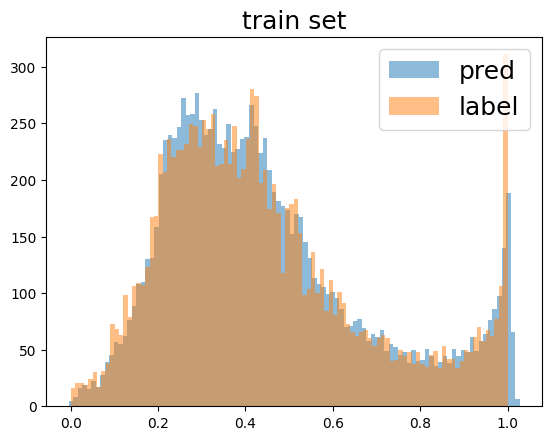

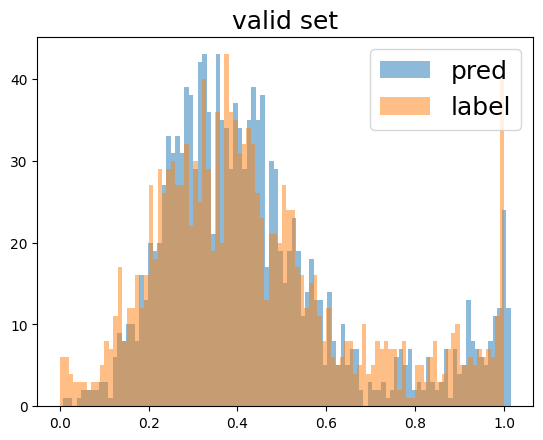

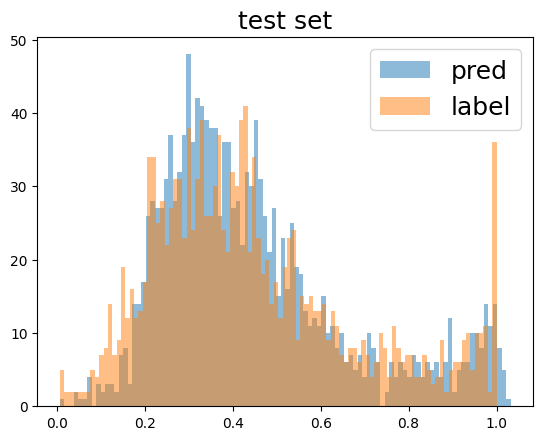

In [51]:
plt.hist(train_pred, bins=100, alpha = 0.5, label = 'pred')
plt.hist(train_label, bins=100, alpha = 0.5, label = 'label')
plt.legend(fontsize=18)
plt.title('train set' ,fontsize=18)
plt.show()
plt.hist(valid_pred, bins=100, alpha = 0.5, label = 'pred')
plt.hist(valid_label, bins=100, alpha = 0.5, label = 'label')
plt.legend(fontsize=18)
plt.title('valid set' ,fontsize=18)
plt.show()
plt.hist(test_pred, bins=100, alpha = 0.5, label = 'pred')
plt.hist(test_label, bins=100, alpha = 0.5, label = 'label')
plt.legend(fontsize=18)
plt.title('test set' ,fontsize=18)
plt.show()

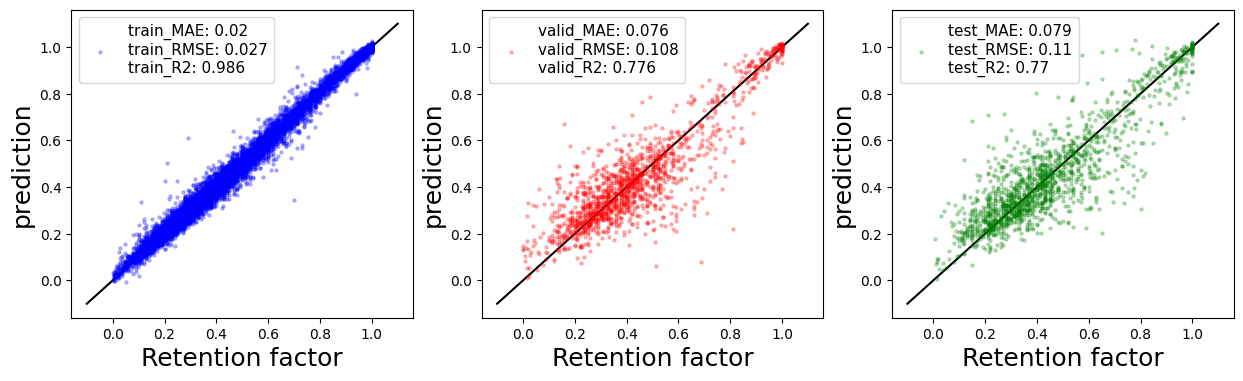

In [52]:
# Rf 라벨일 경우

def r2(preds, targets):
    mean = np.sum(targets)/len(targets)
    ss_res = np.sum((targets - preds) ** 2)
    ss_tot = np.sum((targets - mean) ** 2)
    return 1- ss_res / ss_tot 

train_mae = np.mean(np.abs(train_pred-train_label)).item()
valid_mae = np.mean(np.abs(valid_pred-valid_label)).item()
test_mae = np.mean(np.abs(test_pred-test_label)).item()

# 각 세트에 대한 RMSE
train_rmse = np.sqrt(np.mean((train_pred - train_label)**2)).item()
valid_rmse = np.sqrt(np.mean((valid_pred - valid_label)**2)).item()
test_rmse = np.sqrt(np.mean((test_pred - test_label)**2)).item()


train_r2 = r2(train_pred, train_label).item()
valid_r2 = r2(valid_pred, valid_label).item()
test_r2 = r2(test_pred, test_label).item()


import matplotlib.pyplot as plt

fig,axs = plt.subplots(1,3,figsize=(15,4))

x_line=np.linspace(-0.1,1.1,100)
y_line=x_line

for i in range(3):
    fig.set_facecolor('white')
    axs[i].plot(x_line, y_line, c='black', zorder=1)

    if i==0:
        axs[i].scatter(train_label.flatten(), train_pred.flatten(), c='blue',s=5, zorder=2, alpha = 0.25 , label = f'train_MAE: {round(train_mae,3)}\ntrain_RMSE: {round(train_rmse,3)}\ntrain_R2: {round(train_r2,3)}')
    elif i==1:
        axs[i].scatter(valid_label.flatten(), valid_pred.flatten(), c='red',s=5, zorder=3, alpha = 0.25, label = f'valid_MAE: {round(valid_mae,3)}\nvalid_RMSE: {round(valid_rmse,3)}\nvalid_R2: {round(valid_r2,3)}')
    elif i==2:
        axs[i].scatter(test_label.flatten(), test_pred.flatten(), c='green',s=5, zorder=3, alpha = 0.25, label = f'test_MAE: {round(test_mae,3)}\ntest_RMSE: {round(test_rmse,3)}\ntest_R2: {round(test_r2,3)}')
    axs[i].set_xlabel('Retention factor', fontsize = 18)
    axs[i].set_ylabel('prediction', fontsize = 18)
    axs[i].legend(loc='upper left', fontsize = 11)
    #axs[i].set_xlim(-0.1, 1.1)
    #axs[i].set_ylim(-0.1, 1.1)


In [ ]:
figure_path = '/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/Figure_data/parity_plot/BLI_GAT'
a=pd.DataFrame({
    'test_label' : test_label, 'test_pred': test_pred,
})
a.to_csv(f'{figure_path}/patrity_test.csv', index=False)

: 

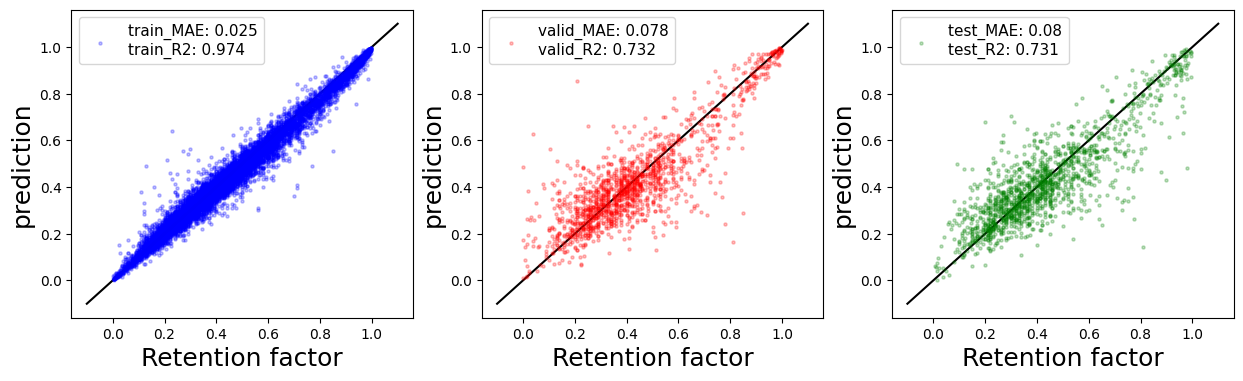

In [ ]:
# 역 시그모이드 라벨 썼을 경우우

"""def E2Rf(E):
    return 1 / (1 + np.exp(-E))

def r2(preds, targets):
    mean = np.sum(targets)/len(targets)
    ss_res = np.sum((targets - preds) ** 2)
    ss_tot = np.sum((targets - mean) ** 2)
    return 1- ss_res / ss_tot 

train_pred = E2Rf(train_pred)
train_label = E2Rf(train_label)
valid_pred = E2Rf(valid_pred)
valid_label = E2Rf(valid_label)
test_pred = E2Rf(test_pred)
test_label = E2Rf(test_label)

train_mae = np.mean(np.abs(train_pred-train_label)).item()
valid_mae = np.mean(np.abs(valid_pred-valid_label)).item()
test_mae = np.mean(np.abs(test_pred-test_label)).item()

train_r2 = r2(train_pred, train_label).item()
valid_r2 = r2(valid_pred, valid_label).item()
test_r2 = r2(test_pred, test_label).item()


import matplotlib.pyplot as plt

fig,axs = plt.subplots(1,3,figsize=(15,4))

x_line=x_line = np.linspace(-0.1, 1.1, 100)
y_line=x_line

for i in range(3):
    fig.set_facecolor('white')
    axs[i].plot(x_line, y_line, c='black', zorder=1)
    if i==0:
        axs[i].scatter(train_label.flatten(), train_pred.flatten(), c='blue',s=5, zorder=2, alpha = 0.25 , label = f'train_MAE: {round(train_mae,3)}\ntrain_R2: {round(train_r2,3)}')
    elif i==1:
        axs[i].scatter(valid_label.flatten(), valid_pred.flatten(), c='red',s=5, zorder=3, alpha = 0.25, label = f'valid_MAE: {round(valid_mae,3)}\nvalid_R2: {round(valid_r2,3)}')
    elif i==2:
        axs[i].scatter(test_label.flatten(), test_pred.flatten(), c='green',s=5, zorder=3, alpha = 0.25, label = f'test_MAE: {round(test_mae,3)}\ntest_R2: {round(test_r2,3)}')
    axs[i].set_xlabel('Retention factor', fontsize = 18)
    axs[i].set_ylabel('prediction', fontsize = 18)
    axs[i].legend(loc='upper left', fontsize = 11)
    #axs[i].set_xlim(-0.1, 1.1)
    #axs[i].set_ylim(-0.1, 1.1)"""

## outlier 조사(shuffle = False) 및 기타 분석 

In [80]:
train_index = np.hstack([np.asarray(id_tensor.view(-1)) for id_tensor in train_id])
train_pred_manager = dict(zip(train_index, train_pred))

from copy import deepcopy

train_set_check = deepcopy(train_set)
train_pred_ = [train_pred_manager[i] for i in train_set['sample_id']]
train_set_check['train_pred'] = train_pred_
train_set_check['error'] = train_set_check['Rf'] - train_set_check['train_pred']
train_set_check

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id,train_pred,error
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers,0,0.503239,0.076761
1,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,2,0.692635,-0.002635
2,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,3,0.793204,-0.013204
3,BrCCCCCCNc1ccccc1,CCCCCC,CCOC(C)=O,0.789299,0.210701,0.480000,C,D4C,average of several papers,6,0.525835,-0.045835
4,BrCCc1cccc2ccccc12,CCCCCC,CCOC(C)=O,0.882244,0.117756,0.630000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,7,0.679128,-0.049128
...,...,...,...,...,...,...,...,...,...,...,...,...
11792,c1ccc(-c2ccccn2)nc1,ClCCl,CO,0.984461,0.015539,0.052081,C,benchmark,exp (benchmark,14696,0.056746,-0.004665
11793,c1ccc(CNCc2ccccc2)cc1,CCCCCC,CCOCC,0.443636,0.556364,0.280306,C,benchmark,exp (benchmark,14697,0.249614,0.030692
11794,c1ccc(CNCc2ccccc2)cc1,CCCCCC,CCOCC,0.614610,0.385390,0.185208,C,benchmark,exp (benchmark,14698,0.217870,-0.032662
11795,c1ccc2[nH]ccc2c1,CCCCCC,CCOCC,0.443636,0.556364,0.764446,C,benchmark,exp (benchmark,14699,0.651782,0.112664


In [81]:
valid_index = np.hstack([np.asarray(id_tensor.view(-1)) for id_tensor in valid_id])
valid_pred_manager = dict(zip(valid_index, valid_pred))

from copy import deepcopy
from scipy.special import softplus

valid_set_check = deepcopy(valid_set)
valid_pred_ = [valid_pred_manager[i] for i in valid_set['sample_id']]
valid_set_check['valid_pred'] = valid_pred_
valid_set_check['error'] = valid_set_check['Rf'] - valid_set_check['valid_pred']
valid_set_check

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id,valid_pred,error
0,BrC1C(Br)(Br)C12CCOCC2,CCCCC,CCOCC,0.890324,0.109676,0.500000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,5,0.292703,0.207297
1,Brc1ccc(/C(=N\C(c2ccccc2)c2ccccc2)N2CCOCC2)cc1,CCCCCC,CCOC(C)=O,0.428314,0.571686,0.670000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,16,0.616333,0.053667
2,Brc1nc2ccccc2c(Br)c1Br,CCCCCC,CCOCC,0.975532,0.024468,0.230000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,72,0.437549,-0.207549
3,C#CC#CC(OCC#CC)c1cccc(C)c1,CCCCCC,CCOC(C)=O,0.973999,0.026001,0.380000,C,D4C,average of several papers,77,0.430923,-0.050923
4,C#CC(O)c1ccc(OC)cc1,CCCCC,CCOC(C)=O,0.772206,0.227794,0.420000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,94,0.337062,0.082938
...,...,...,...,...,...,...,...,...,...,...,...,...
1435,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark,14706,0.759741,-0.655934
1436,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark,14707,0.617971,-0.540729
1437,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark,14708,0.505902,-0.465078
1438,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark,14709,0.444760,-0.398801


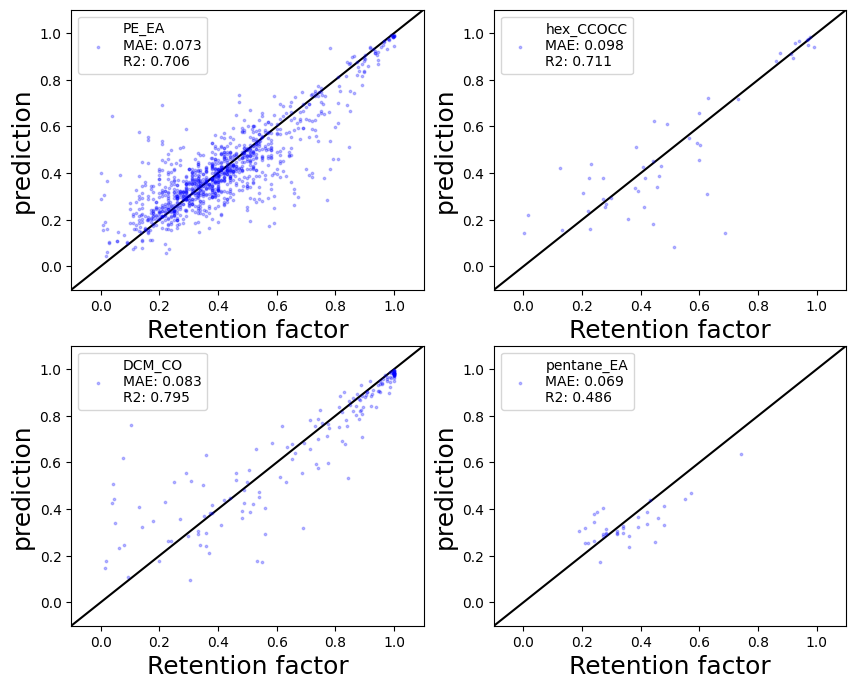

In [82]:
PE_EA_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'CCOC(C)=O', 'CCCCCC'} for i in valid_set_check.index]
valid_set_check_PE_EA = valid_set_check[PE_EA_mask]

DCM_CO_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'ClCCl', 'CO'} for i in valid_set_check.index]
valid_set_check_DCM_CO = valid_set_check[DCM_CO_mask]

hex_CCOCC_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'CCCCCC', 'CCOCC'} for i in valid_set_check.index]
valid_set_check_hex_CCOCC = valid_set_check[hex_CCOCC_mask]

pentane_EA_mask = [set(valid_set_check.loc[i, ['elu1_smiles','elu2_smiles']]) == {'CCCCC', 'CCOC(C)=O'} for i in valid_set_check.index]
valid_set_check_pentane_EA = valid_set_check[pentane_EA_mask]

elu_sys_valid = [valid_set_check_PE_EA, valid_set_check_DCM_CO, valid_set_check_hex_CCOCC, valid_set_check_pentane_EA]
elu_sys_list = ['PE_EA', 'DCM_CO', 'hex_CCOCC', 'pentane_EA']

def mae_(preds, targets):
    return round(np.mean(np.abs(preds-targets)), 3)

def r2(preds, targets):
    mean = np.sum(targets)/len(targets)
    ss_res = np.sum((targets - preds) ** 2)
    ss_tot = np.sum((targets - mean) ** 2)
    return round(1- ss_res / ss_tot, 3)

    

import matplotlib.pyplot as plt

fig,axs = plt.subplots(2,2,figsize=(10,8))

x_line=np.arange(-2,3)
y_line=np.arange(-2,3)

for i in range(4):
    fig.set_facecolor('white')
    axs[i%2, i//2].plot(x_line, y_line, c='black', zorder=1)

    axs[i%2, i//2].scatter(
        elu_sys_valid[i]['Rf'], elu_sys_valid[i]['valid_pred'],
        c='blue',s=3, zorder=2, alpha = 0.25,
        label = f'{elu_sys_list[i]}\nMAE: {mae_(elu_sys_valid[i]["valid_pred"], elu_sys_valid[i]["Rf"])}\nR2: {r2(elu_sys_valid[i]["valid_pred"], elu_sys_valid[i]["Rf"])}')
    axs[i%2, i//2].set_xlabel('Retention factor', fontsize = 18)
    axs[i%2, i//2].set_ylabel('prediction', fontsize = 18)
    axs[i%2, i//2].legend(loc='upper left', fontsize = 10)

    axs[i%2, i//2].set_xlim(-0.1, 1.1)
    axs[i%2, i//2].set_ylim(-0.1, 1.1)

## TLC의 화학적 분석

In [ ]:
# ==============================
# 경향성 및 분석 용 set 

In [44]:
united_

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,Rf_type,DataSource,doi,sample_id
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCCCCC,CCOC(C)=O,0.937438,0.062562,0.580000,C,D4C,average of several papers,0
1,BrC(Br)=Cn1c2ccccc2c2ccccc21,CCCCC,CCOC(C)=O,0.884089,0.115911,0.900000,C,D4C,average of several papers,1
2,BrC/C=C\COC1CCCCO1,CCCCCC,CCOCC,0.650419,0.349581,0.690000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.4...,2
3,BrC1=C(Br)C(c2ccccc2)OC1,CCCCCC,CCOC(C)=O,0.749803,0.250197,0.780000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.3...,3
4,BrC1=C[SH](c2ccccc2)C=N1,CCCCCC,CCOC(C)=O,0.870849,0.129151,0.450000,C,D4C,https://pubs.acs.org/doi/10.1021/acs.orglett.5...,4
...,...,...,...,...,...,...,...,...,...,...
14706,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.863674,0.136326,0.103807,C,benchmark,exp (benchmark,14706
14707,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.926851,0.073149,0.077242,C,benchmark,exp (benchmark,14707
14708,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.950015,0.049985,0.040824,C,benchmark,exp (benchmark,14708
14709,c1cnc2c(c1)ccc1cccnc12,ClCCl,CO,0.969397,0.030603,0.045959,C,benchmark,exp (benchmark,14709


In [45]:
valid_uniq_smiles_list = list(united_['Smiles'].drop_duplicates())

aug_smiles = [smiles  for smiles in valid_uniq_smiles_list for i in range(11)]
aug_elu1_smiles = ['CCOC(C)=O' for i in range(len(aug_smiles))]
aug_elu2_smiles = ['CCCCCC' for i in range(len(aug_smiles))]
aug_ratio1 = [round(i,1) for ii in range(len(valid_uniq_smiles_list)) for i in np.arange(0,1.05,0.1)]
aug_ratio2 = np.round(1- np.array(aug_ratio1), 1)

trend_set = pd.DataFrame({
    'Smiles': aug_smiles,
    'elu1_smiles':aug_elu1_smiles,
    'elu2_smiles':aug_elu2_smiles,
    'ratio1':aug_ratio1,
    'ratio2':aug_ratio2,
    'Rf':[np.nan for i in range(len(aug_smiles))]
})

trend_set['sample_id'] = trend_set.index
trend_set

,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id
0,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0
1,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1
2,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2
3,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3
4,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4
...,...,...,...,...,...,...,...
126341,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,126341
126342,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,126342
126343,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,126343
126344,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,126344


In [73]:
trend_set.to_csv('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/DB/Rf/United_DB_trend_test.csv')

In [46]:
trend_set = pd.read_csv('/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/DB/Rf/United_DB_trend_test.csv')

In [47]:
# 경향성 test

from model_architecture import GCN_eluent_interaction_5 as model_5
#from model_architecture import GCN_eluent_interaction_7_light as model_7_light

device = torch.device('cuda')
model = model_5().to(device)
# model = model_7_light(version = 'all').to(device)

opt_ckpt = torch.load((path + '/opt_checkpoint.pt'))
model.load_state_dict(opt_ckpt['model_state_dict'])


mean = np.load('./standardization/mean.npy')
std = np.load('./standardization/std.npy')


# ====================================================
print('>>> graph 만드는 중...')
compound_trend_set = MolToGraph('Smiles', path_raw, 'United_DB_trend_test.csv', 'trend_test/compound_valid.pt', molecular_param = False, augment = True)
elu1_trend_set = MolToGraph('elu1_smiles', path_raw, 'United_DB_trend_test.csv', 'trend_test/elu1_valid.pt', molecular_param = False, augment = True)
elu2_trend_set = MolToGraph('elu2_smiles', path_raw, 'United_DB_trend_test.csv', 'trend_test/elu2_valid.pt', molecular_param = False, augment = True)

# ====================================================
print('>>> compound랑 eluent graph 모으는 중...')
graph_trend_set = TripleGraphDataset(
    compound_trend_set,
    elu1_trend_set,
    elu2_trend_set
)

#=====================================================
print('>>> dataloader 만드는 중...')
trend_loader = DataLoader(graph_trend_set, batch_size =500, shuffle=False)

# ====================================================
print('>>> 예측 시작!')

trend_pred=[]
trend_id=[]
model.eval()
with torch.no_grad():
    for com_trend, elu1_trend, elu2_trend in trend_loader:
        trend_id.append(com_trend.sample_id)
        com_trend_batch = com_trend.to(device)
        elu1_trend_batch = elu1_trend.to(device)
        elu2_trend_batch = elu2_trend.to(device)
        pred = model(com_trend_batch, elu1_trend_batch, elu2_trend_batch)
        trend_pred.append(pred.cpu())

trend_pred = np.vstack(trend_pred)
trend_pred = inverse_standardization(trend_pred, mean, std)
trend_pred = trend_pred.reshape(-1)

print('>> 예측 완료')

>>> graph 만드는 중...
>>> compound랑 eluent graph 모으는 중...
>>> dataloader 만드는 중...
>>> 예측 시작!
>> 예측 완료


In [50]:
trend_pred = np.clip(trend_pred,0,1)

In [51]:
trend_index = np.hstack([np.asarray(id_tensor.view(-1)) for id_tensor in trend_id])
trend_pred_manager = dict(zip(trend_index, trend_pred.reshape(-1)))

from copy import deepcopy

trend_set_check = deepcopy(trend_set)
trend_pred_ = [trend_pred_manager[i] for i in trend_set['sample_id']]
trend_set_check['trend_pred'] = trend_pred_
trend_set_check

,Unnamed: 0,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id,trend_pred
0,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0,0.429261
1,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1,0.547815
2,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2,0.606622
3,3,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3,0.590349
4,4,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4,0.542611
...,...,...,...,...,...,...,...,...,...
126341,126341,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,126341,0.565521
126342,126342,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,126342,0.627171
126343,126343,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,126343,0.683541
126344,126344,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,126344,0.703489


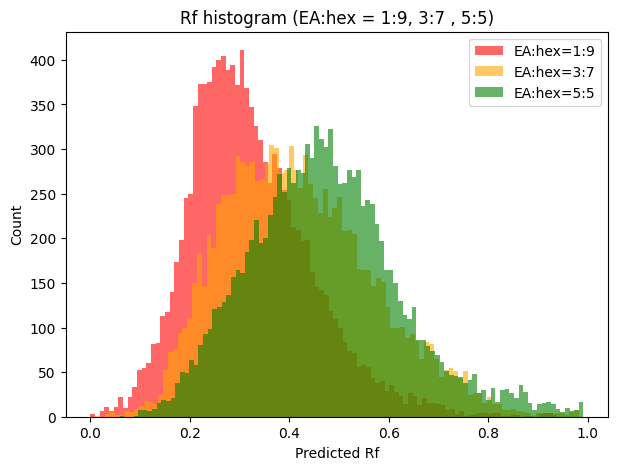

In [52]:
#hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in np.arange(0,1.05,0.1)]
hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in [0.1, 0.3, 0.5]]

fig = plt.figure(figsize=(7,5))
color=['red', 'orange', 'green']
data_label = ['1:9', '3:7', '5:5']
for i, data in enumerate(hists):
    plt.hist(
        data,
        alpha=0.6,
        bins = 100,
        color = color[i],
        density=False,
        label=f'EA:hex={data_label[i]}')

plt.title('Rf histogram (EA:hex = 1:9, 3:7 , 5:5)')
plt.xlabel('Predicted Rf')
plt.ylabel('Count')
plt.legend()
plt.show()


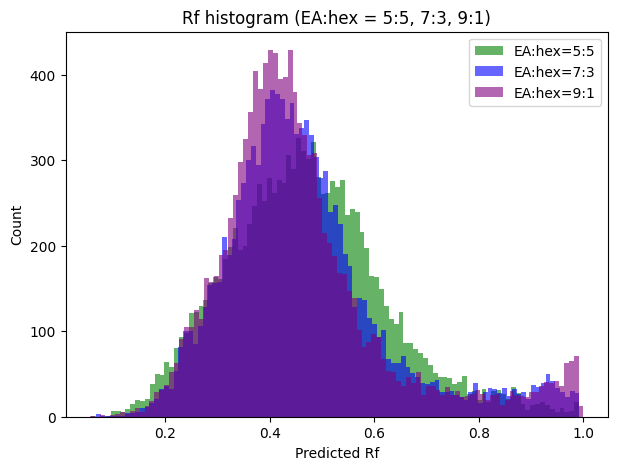

In [53]:
#hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in np.arange(0,1.05,0.1)]
hists = [list(trend_set_check[trend_set_check['ratio1']==np.round(i,1)]['trend_pred']) for i in [0.5, 0.7, 0.9]]

fig = plt.figure(figsize=(7,5))
color=['green', 'blue', 'purple']
data_label = ['5:5', '7:3', '9:1']
for i, data in enumerate(hists):
    plt.hist(
        data,
        alpha=0.6,
        bins = 100,
        color = color[i],
        density=False,
        label=f'EA:hex={data_label[i]}')

plt.title('Rf histogram (EA:hex = 5:5, 7:3, 9:1)')
plt.xlabel('Predicted Rf')
plt.ylabel('Count')
plt.legend()
plt.show()

In [54]:
trend_set_check

,Unnamed: 0,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,sample_id,trend_pred
0,0,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.0,1.0,NaN,0,0.429261
1,1,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.1,0.9,NaN,1,0.547815
2,2,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.2,0.8,NaN,2,0.606622
3,3,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.3,0.7,NaN,3,0.590349
4,4,Br/C(=C\C1SCCCS1)c1ccccc1,CCOC(C)=O,CCCCCC,0.4,0.6,NaN,4,0.542611
...,...,...,...,...,...,...,...,...,...
126341,126341,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.6,0.4,NaN,126341,0.565521
126342,126342,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.7,0.3,NaN,126342,0.627171
126343,126343,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.8,0.2,NaN,126343,0.683541
126344,126344,c1cnc2c(c1)ccc1cccnc12,CCOC(C)=O,CCCCCC,0.9,0.1,NaN,126344,0.703489


In [85]:
# Rf trajectory (EA ratio 0~1)
rf_trace_list = np.array([list(trend_set_check['trend_pred'][11*i:11*(i+1)]) for i in range(len(valid_uniq_smiles_list))] )

# Rf mean (EA ratio 0~1)
rf_level = rf_trace_list.mean(axis=1, keepdims=True)

# Rf range (EA ratio 0~1)
rf_amplitude = (rf_trace_list.max(axis=1) - rf_trace_list.min(axis=1)).reshape(-1,1)

# Rf start,end (EA ratio0~1)
rf_end2end = rf_trace_list[:,[0,10]]

# Rf trajectory shape (EA ratio 0~1)
# L2 norm으로 나누어서 11차원 벡터의 크기를 제거하고 방향만 남김 --> 즉 shape만 남김
rf_delta_list=np.diff(rf_trace_list, axis=1)
delta_L2_norm = np.linalg.norm(rf_delta_list, axis=1, keepdims=True)
rf_trace_shape = rf_delta_list/delta_L2_norm

#X = np.hstack([rf_level, rf_amplitude, rf_trace_shape])
#X = np.hstack([rf_amplitude,rf_trace_shape])
#X = np.hstack([rf_trace_list,rf_trace_shape])
X = np.hstack([rf_trace_list])

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# X_scaled[:,0] *= 0.5   # level weight
# X_scaled[:,1] *= 1.0   # amplitude weight
# X_scaled[:,2:] *= 2.0  # shape weight
# X_scaled[:,3:] *= 2.0  # shape weight


In [86]:
from sklearn.cluster import KMeans

k = 4  # 보통 3~6 사이에서 elbow로 결정
kmeans = KMeans(n_clusters=k, random_state=0)
labels = kmeans.fit_predict(X)

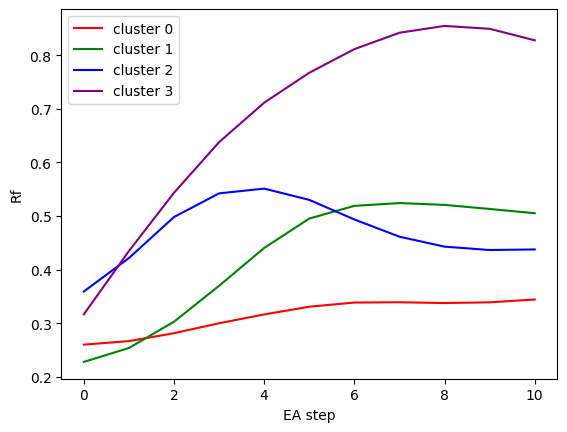

In [101]:
cluster_means = []

for c in range(k):
    mean_trace = np.array(rf_trace_list)[labels == c].mean(axis=0)
    cluster_means.append(mean_trace.mean())   # 전체 평균 Rf

order = np.argsort(cluster_means)

label_map = {old:new for new, old in enumerate(order)}

new_labels = np.array([label_map[l] for l in labels])

import matplotlib.pyplot as plt
color= ['red', 'green', 'blue', 'purple']
for i,c in enumerate(range(k)):
    mean_trace = np.array(rf_trace_list)[new_labels == c].mean(axis=0)
    plt.plot(mean_trace, color = color[i], label=f'cluster {c}')

plt.legend()
plt.xlabel('EA step')
plt.ylabel('Rf')
plt.show()

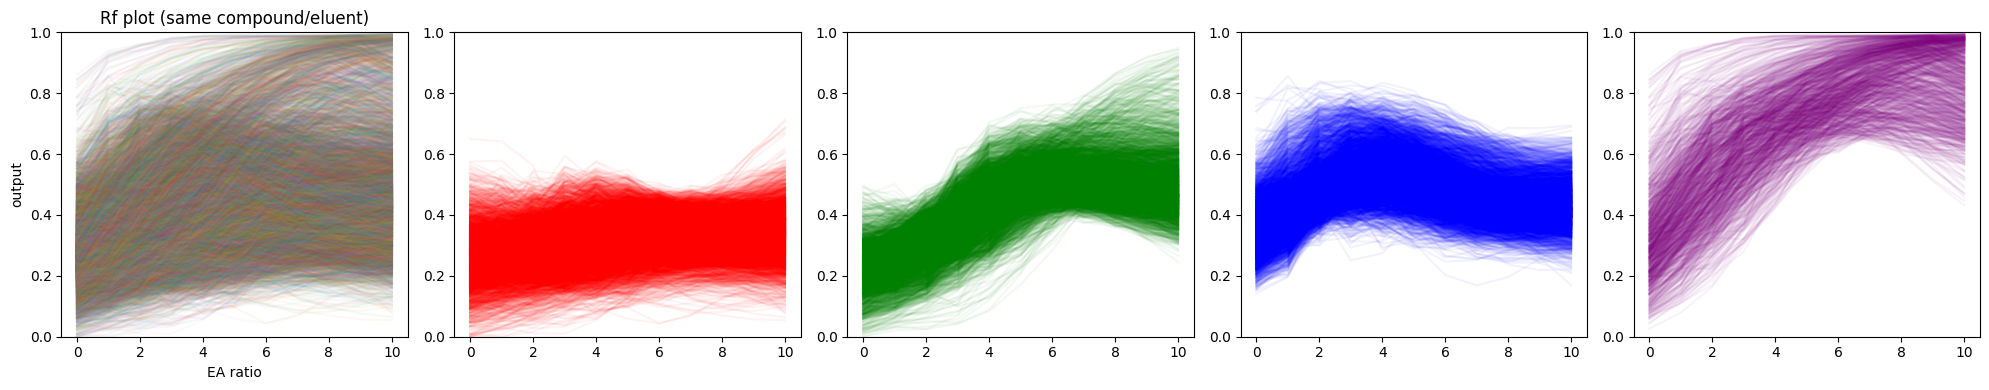

In [102]:
# ============== 같은 분자 내에서 용매 비율 비교 ==========================

rf_trace_list = [list(trend_set_check['trend_pred'][11*i:11*(i+1)]) for i in range(len(valid_uniq_smiles_list))] 


fig, axs = plt.subplots(1,5,figsize=(20,4))
for i, data in enumerate(rf_trace_list):
    axs[0].plot(
        np.arange(0,11,1),
        data,
        alpha=0.05,
    )
axs[0].set_title('Rf plot (same compound/eluent)')
axs[0].set_xlabel('EA ratio')
axs[0].set_ylabel('output')
axs[0].set_ylim(0,1)
for output, group in zip(rf_trace_list, new_labels):
# for output, group in zip(rf_trace_list, labels[30000:len(valid_uniq_smiles_list)]):
    if group==0:
        color = 'red'
        alpha = 0.05
        axs[1].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[1].set_ylim(0,1)
    elif group==1:
        color = 'green'
        alpha = 0.05
        axs[2].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[2].set_ylim(0,1)
    elif group==2:
        color = 'blue'
        alpha = 0.05
        axs[3].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[3].set_ylim(0,1)
    elif group==3:
        color = 'purple'
        alpha = 0.05
        axs[4].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
        axs[4].set_ylim(0,1)
    # elif group==4:
    #     color = 'black'
    #     alpha = 0.05
    #     axs[5].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
    #     axs[5].set_ylim(0,1)
    # elif group==5:
    #     color = 'gray'
    #     alpha = 0.05
    #     axs[6].plot(np.arange(0,11,1), output, color = color, alpha=alpha)
    #     axs[6].set_ylim(0,1)



# axs[1].set_title('output plot (same compound/eluent)')
# axs[1].set_xlabel('EA ratio')
# axs[1].set_ylabel('model output')

plt.tight_layout()
plt.show()

In [93]:
group0=[]
group1=[]
group2=[]
group3=[]
# group4=[]
# group5=[]
for smiles,group in zip(valid_uniq_smiles_list, new_labels):
    if group ==0:
        group0.append(smiles)
    elif group ==1:
        group1.append(smiles)
    elif group==2:
        group2.append(smiles)
    elif group==3:
        group3.append(smiles)
    # elif group==4:
    #     group4.append(smiles)
    # elif group==5:
    #     group5.append(smiles)

/home/ufslab223/anaconda3/envs/ksw_pyg/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:343: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


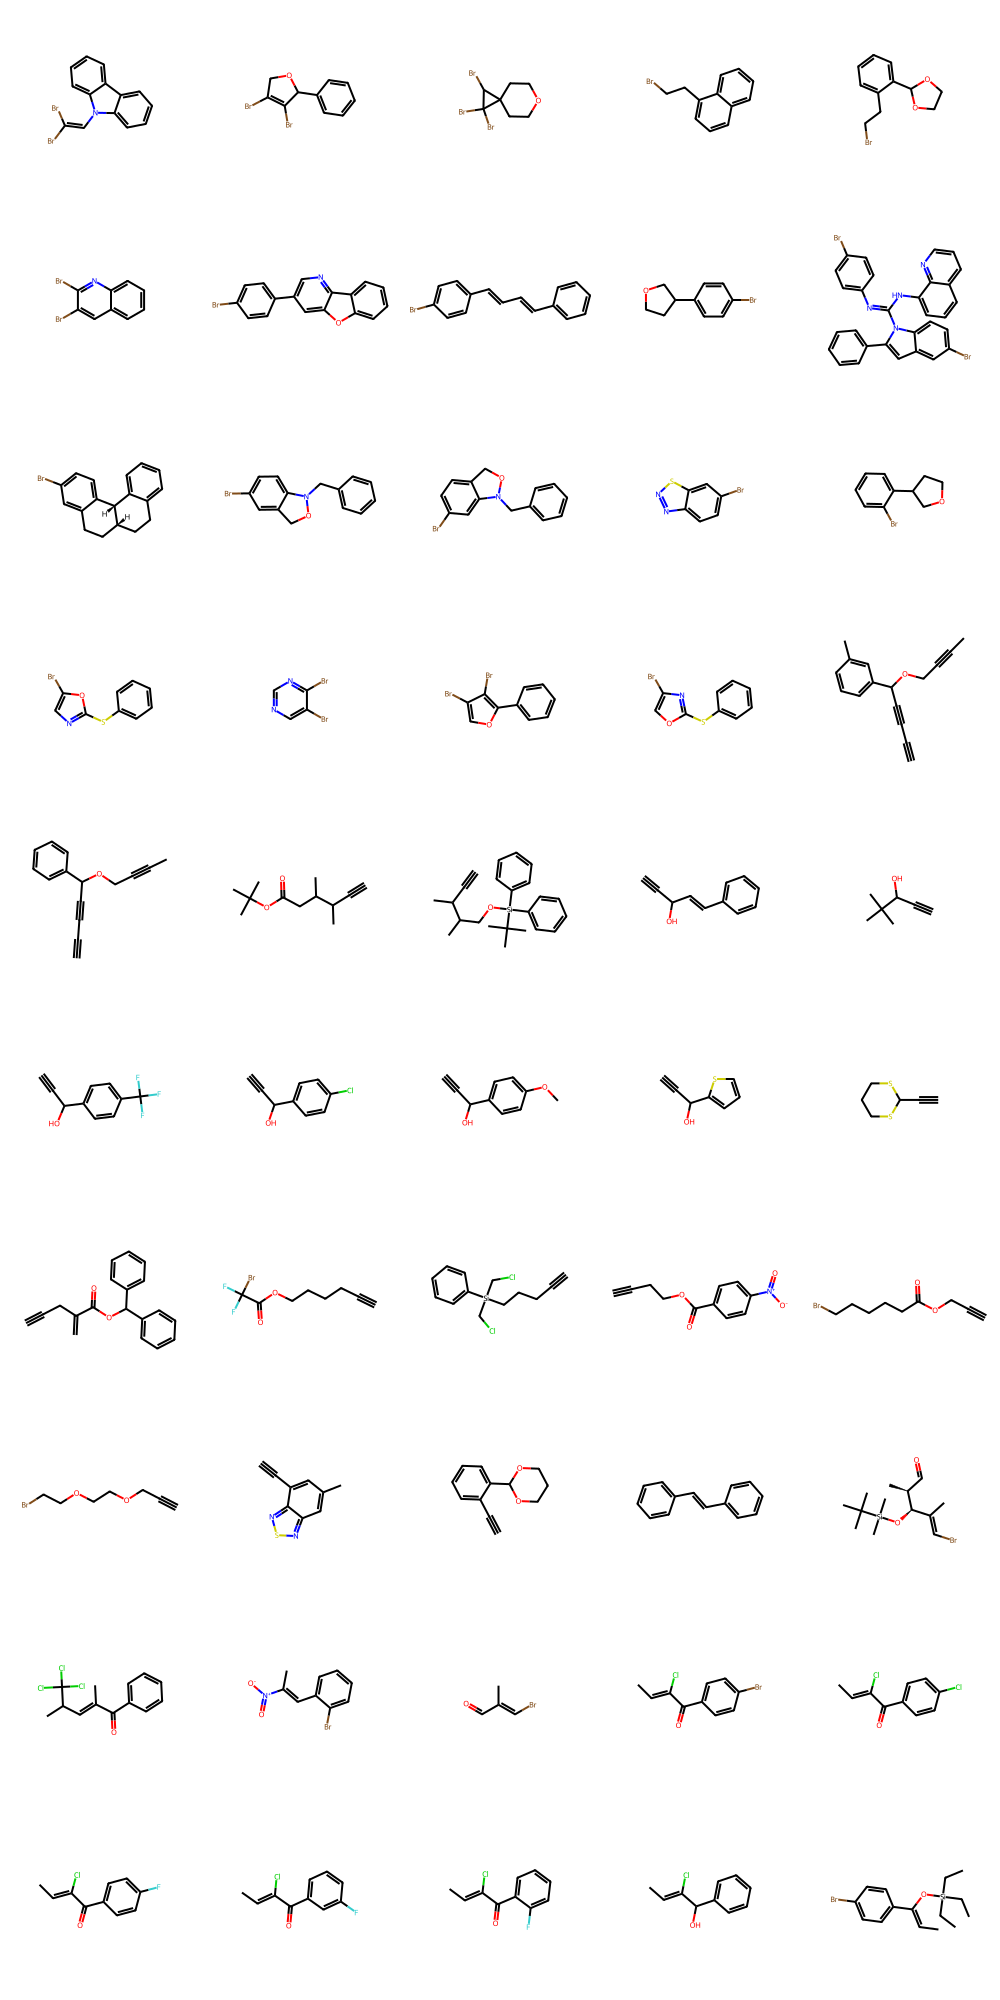

In [166]:
from rdkit import Chem
from rdkit.Chem import Draw

mols = [Chem.MolFromSmiles(smi) for smi in group2]
img = Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(200,200))
img

In [90]:
# def get_HB_per_conjugated_atom_count(smiles):

#     mol = Chem.MolFromSmiles(smiles)
#     if mol is None:
#         return None

#     # 방향족 원자 수 카운트
#     aromatic_atom_count = sum(1 for atom in mol.GetAtoms() if atom.GetIsAromatic())

#     # 공액에 참여하는 atom 수
#     conjugated_atom_idxs = set()
#     for bond in mol.GetBonds():
#         if bond.GetIsConjugated():
#             conjugated_atom_idxs.add(bond.GetBeginAtomIdx())
#             conjugated_atom_idxs.add(bond.GetEndAtomIdx())

#     # 공액계 추정: 방향족+이중결합 원자
#     conj_atom_count = aromatic_atom_count + len(double_bond_atom_idxs)
#     return conj_atom_count

def hba(smiles):
    mol = Chem.MolFromSmiles(smiles)
    hba = Chem.rdMolDescriptors.CalcNumHBA(mol)
    return hba

def hbd(smiles):
    mol = Chem.MolFromSmiles(smiles)
    hbd = Chem.rdMolDescriptors.CalcNumHBD(mol)
    return hbd

def hb(smiles):
    mol = Chem.MolFromSmiles(smiles)
    hbd = Chem.rdMolDescriptors.CalcNumHBD(mol)
    hba = Chem.rdMolDescriptors.CalcNumHBA(mol)
    return hba+hbd

def tpsa(smiles):
    mol = Chem.MolFromSmiles(smiles)
    tpsa = Descriptors.TPSA(mol)
    return tpsa

def asa(smiles):
    mol = Chem.MolFromSmiles(smiles)
    asa = rdMolDescriptors.CalcLabuteASA(mol)
    return asa

def mw(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mw = Descriptors.MolWt(mol)
    return mw


In [ ]:
"""from rdkit import Chem
from rdkit.Chem import AllChem, rdFreeSASA

def surface_area(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol) # 수소 원자 추가 필수
    AllChem.EmbedMolecule(mol) # 3D 구조 생성

    # 원자 반지름 리스트 추출
    radii = rdFreeSASA.classifyAtoms(mol)

    # SASA 계산
    sasa = rdFreeSASA.CalcSASA(mol, radii)
    return sasa"""

In [116]:
print(len(group0)/len(group1),len(group1)/len(group1), len(group2)/len(group1))

4.139673105497772 1.0 3.3937592867756314


0
1
2
3


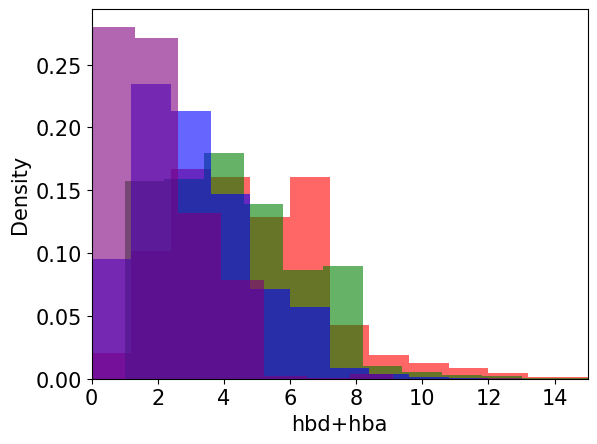

In [100]:

g0 = list(map(hb, group0))

g1 = list(map(hb, group1))

g2 = list(map(hb, group2))

g3 = list(map(hb, group3))

# g4 = list(map(polarity_per_mol, group4))

# g5 = list(map(polarity_per_mol, group5))

gs = [g0, g1,g2,g3]#,g4,g5]

color= ['red', 'green', 'blue','purple']#, 'black', 'gray']
bin = [30,20,10,10]
for i, data in enumerate(gs):
    print(i)
    plt.hist(
        data,
        color=color[i],
        bins=bin[i],
        alpha = 0.6,
        density=True
    )
plt.xlabel('hbd+hba', size = 15)
plt.ylabel('Density', size = 15)
plt.xticks(size = 15)
plt.yticks(size = 15)
plt.xlim(0,15)
plt.show()

0
1
2
3


(0.0, 200.0)

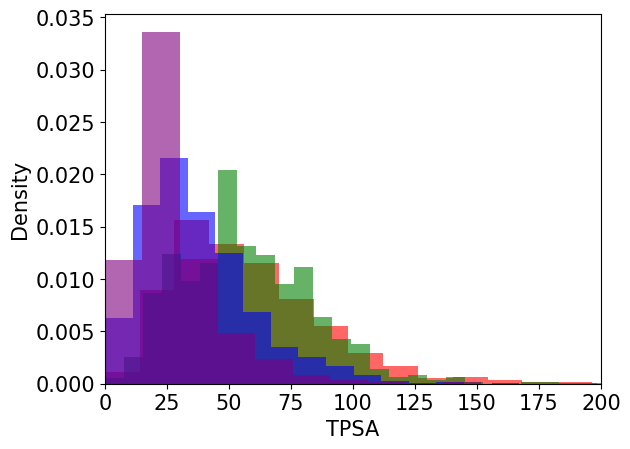

In [104]:

g0 = list(map(tpsa, group0))

g1 = list(map(tpsa, group1))

g2 = list(map(tpsa, group2))

g3 = list(map(tpsa, group3))

# g4 = list(map(polarity_per_mol, group4))

# g5 = list(map(polarity_per_mol, group5))

gs = [g0, g1,g2,g3]#,g4,g5]

color= ['red', 'green', 'blue', 'purple']#, 'black', 'gray']
bin = [30,30,15,10]
for i, data in enumerate(gs):
    print(i)
    plt.hist(
        data,
        color=color[i],
        bins=bin[i],
        alpha = 0.6,
        density=True
    )
plt.xlabel('TPSA', size = 15)
plt.ylabel('Density', size = 15)
plt.xticks(size = 15)
plt.yticks(size = 15)
plt.xlim(0,200)

In [ ]:
# T-sne
# 기존 D4C 데이터베이스와 비교
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from tqdm import tqdm


total = group1+group2+group3

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, countSimulation=True)
X = []
for smiles in tqdm(total):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        fp = generator.GetFingerprint(mol)
        arr = np.zeros((2048,), dtype=int)
        DataStructs.ConvertToNumpyArray(fp, arr)
        X.append(arr)
    else:
        continue


# t-SNE(2048 to 2)
# Check: t-SNE embedding and visualization
tsne = TSNE(n_components=2, random_state=1)
X_tsne = tsne.fit_transform(np.array(X))

# t-SNE Visualization: Draw each group in a different color
plt.figure(figsize=(8,6))
colors = ['blue', 'red', 'green']
start = 0
for i, (group, color) in tqdm(enumerate(zip([group1, group2, group3], colors))):
    end = start + len(group)
    plt.scatter(X_tsne[start:end, 0], X_tsne[start:end, 1], c=color, label=f'group{i+1}', alpha=0.3, s=5)
    start = end

plt.legend()
plt.title('group')
plt.tight_layout()
plt.show()